# TorNet: does five minutes of radar history help?

This completed experiment freezes the pretrained TorNet CNN and trains small
tornado-detection heads on its radar features. Four configurations, three seeds,
one fixed storm-group split: **12 real fits** on **6,414 radar clips** from 2014–2015.

**Result:** averaging two scans won validation. On the held-out test set it improved
average precision from **0.517 to 0.548** versus the original CNN, but produced
**564 false positives instead of 276**, for **69 versus 68 detected positive clips**.
The experiment does not establish an operational improvement.

Read sections 1–3 for the findings. Sections 4–6 contain **all first-party code**,
verification, optional cached replay, and tests. The small `upstream/` directory
contains the authors' required loader and Keras code, with their license.

Use Python 3.11 and `requirements.txt`; see [SETUP.md](SETUP.md). Run this notebook
from the repository root. **Run All verifies saved results and runs synthetic
integrity tests.** It can fetch the pinned 18.8 MB checkpoint once; it does not
acquire the 32.46 GB radar archives or refit the real study.


## 1. The experiment

Two radar scans (current and roughly five minutes earlier) each pass through the
**same frozen 4.67-million-parameter CNN**. Each produces 384 spatially pooled
features. A scaler fitted on current **training** features transforms both scans.
The selected adaptation averages those vectors and trains a **385-parameter
linear head** per seed; final scores average the three heads.

The target is tornado presence in the **current scan**. Temporal averaging tests
persistence and smoothing; it does not learn the direction of storm evolution.

Episodes connected by shared radar dates stay together. Known source-training
episode/event overlap and nearby records were removed before the study split.
Actual terminal-frame labels supply the target; TOR/WRN/NUL are sampling categories.


In [1]:
from pathlib import Path
import json
import os

ROOT = Path.cwd().resolve()
assert (ROOT / "planned_config.json").is_file(), "Open the notebook from the repository root."
os.environ.setdefault("KERAS_BACKEND", "torch")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

get_ipython().run_line_magic("matplotlib", "inline")

import pandas as pd
from IPython.display import display

def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))

LABELS = {
    "baseline": "Current scan / linear",
    "history": "Two-scan mean / linear",
    "hard_negatives": "Warning negatives x2",
    "nonlinear_head": "Current scan / MLP",
    "original_cnn": "Original pretrained CNN",
    "radar_statistics": "Radar-statistics logistic",
    "majority": "Always no tornado",
}
audit = read_json("results/data_audit.json")
display(pd.DataFrame(audit["split_census"]).T[
    ["samples", "positive_samples", "storm_groups", "positive_storm_groups"]
].rename_axis("split"))


,samples,positive_samples,storm_groups,positive_storm_groups
split,,,,
train,3667,438,28,12
val,1325,177,10,8
test,1422,89,10,8


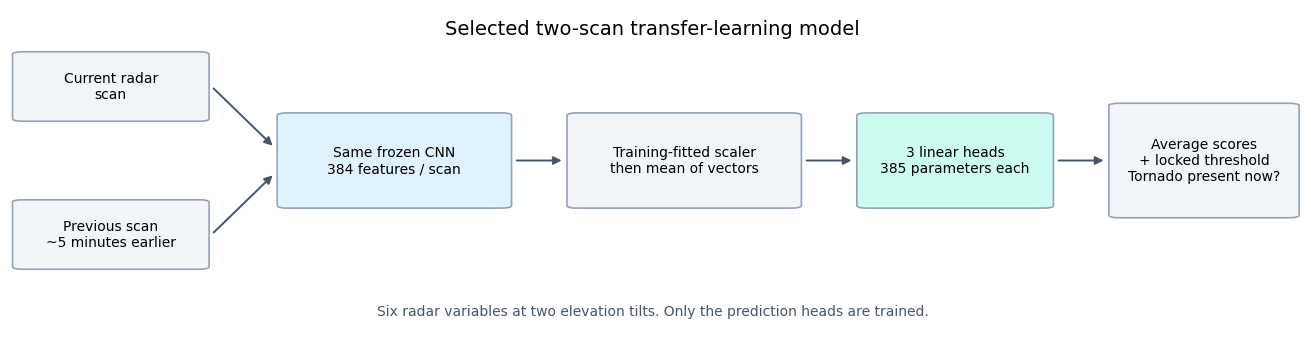

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 3.3), layout="constrained")
ax.set(xlim=(0, 1.025), ylim=(0, 1))
ax.axis("off")

def box(x, y, width, height, text, color):
    ax.add_patch(FancyBboxPatch((x, y), width, height, boxstyle="round,pad=0.008",
                               facecolor=color, edgecolor="#94a3b8", linewidth=1.2))
    ax.text(x + width/2, y + height/2, text, ha="center", va="center", fontsize=10)

def arrow(start, end):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=12,
                                color="#475569", linewidth=1.4))

box(.01, .66, .14, .20, "Current radar\nscan", "#f1f5f9")
box(.01, .20, .14, .20, "Previous scan\n~5 minutes earlier", "#f1f5f9")
box(.22, .39, .17, .28, "Same frozen CNN\n384 features / scan", "#e0f2fe")
box(.45, .39, .17, .28, "Training-fitted scaler\nthen mean of vectors", "#f1f5f9")
box(.68, .39, .14, .28, "3 linear heads\n385 parameters each", "#ccfbf1")
box(.88, .36, .135, .34, "Average scores\n+ locked threshold\nTornado present now?", "#f1f5f9")
arrow((.16, .76), (.21, .57))
arrow((.16, .30), (.21, .49))
for start, end in [((.40, .53), (.44, .53)), ((.63, .53), (.67, .53)), ((.83, .53), (.87, .53))]:
    arrow(start, end)
ax.text(.51, .97, "Selected two-scan transfer-learning model", ha="center", va="top", fontsize=14)
ax.text(.51, .05, "Six radar variables at two elevation tilts. Only the prediction heads are trained.",
        ha="center", color="#475569", fontsize=10)
plt.show()

## 2. What changed, and what happened?

Each configuration changes one factor from the current-scan linear baseline.
Each uses seeds 42, 43, and 44 and 30 training epochs. Validation chooses the
earliest best epoch, configuration, and each model's threshold targeting at least
80% recall. The declared tie rule favors fewer parameters within 0.01 mean AP,
then one scan, then original order. The final holdout is used only after locking
that decision; unselected experimental variants stay on validation.

**Average precision (AP)** measures ranking across thresholds; higher is better.
Precision and recall below describe one validation-selected operating point.


In [3]:
comparison = pd.read_csv(ROOT / "results/experiment_comparison.csv")
validation_table = pd.DataFrame({
    "configuration": comparison.configuration.map(LABELS),
    "mean validation AP": comparison.mean_validation_ap,
    "seed SD": comparison.std_validation_ap,
    "head parameters": comparison.parameters,
    "selected": comparison.selected,
}).set_index("configuration")
display(validation_table.style.format({"mean validation AP": "{:.3f}", "seed SD": "{:.3f}"}))

final = read_json("results/final_test.json")
test_table = pd.DataFrame(final["metrics"]).T
test_table.index = test_table.index.map(LABELS)
display(test_table[["average_precision", "precision", "recall", "tp", "fp"]].style.format({
    "average_precision": "{:.3f}", "precision": "{:.1%}", "recall": "{:.1%}", "tp": "{:.0f}", "fp": "{:.0f}"
}))


,mean validation AP,seed SD,head parameters,selected
configuration,,,,
Current scan / linear,0.658,0.005,385,False
Two-scan mean / linear,0.675,0.001,385,True
Warning negatives x2,0.656,0.005,385,False
Current scan / MLP,0.670,0.007,24705,False


,average_precision,precision,recall,tp,fp
Two-scan mean / linear,0.548,10.9%,77.5%,69,564
Always no tornado,0.063,0.0%,0.0%,0,0
Original pretrained CNN,0.517,19.8%,76.4%,68,276
Radar-statistics logistic,0.142,8.6%,87.6%,78,831
Current scan / linear,0.508,10.9%,78.7%,70,571


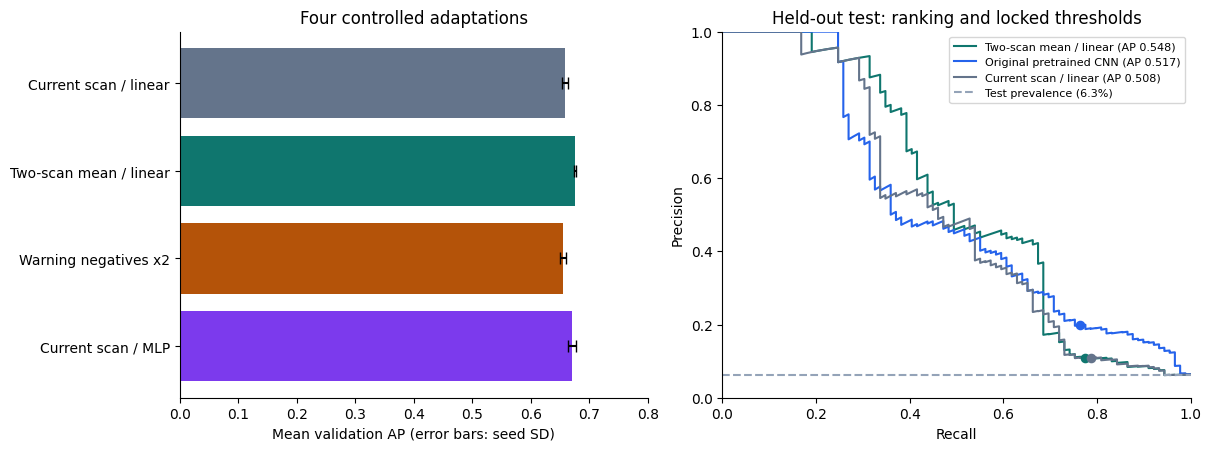

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

predictions = pd.read_csv(ROOT / "results/final_test_predictions.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
colors = ["#64748b", "#0f766e", "#b45309", "#7c3aed"]
axes[0].barh(range(4), comparison.mean_validation_ap, xerr=comparison.std_validation_ap,
             color=colors, capsize=4)
axes[0].set_yticks(range(4), comparison.configuration.map(LABELS))
axes[0].invert_yaxis()
axes[0].set(xlim=(0, .8), xlabel="Mean validation AP (error bars: seed SD)", title="Four controlled adaptations")
for model, color in [("history", "#0f766e"), ("original_cnn", "#2563eb"), ("baseline", "#64748b")]:
    precision, recall, _ = precision_recall_curve(predictions.label, predictions[f"score_{model}"])
    ap = final["metrics"][model]["average_precision"]
    axes[1].plot(recall, precision, color=color, label=f"{LABELS[model]} (AP {ap:.3f})")
    point = final["metrics"][model]
    axes[1].scatter([point["recall"]], [point["precision"]], color=color, s=35, zorder=3)
axes[1].axhline(predictions.label.mean(), linestyle="--", color="#94a3b8", label="Test prevalence (6.3%)")
axes[1].set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall", ylabel="Precision", title="Held-out test: ranking and locked thresholds")
axes[1].legend(fontsize=8, loc="upper right")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.show()


### Learning behavior and selected errors

The learning curves below show all three seeds of the selected adaptation.
Its confusion matrix uses the threshold locked on validation. Examples are
selected after sealing: highest-scoring false positive, lowest-scoring false
negative, and one correct positive sampled with seed 42. These examples help
inspect failure cases; they are not evidence of average performance.

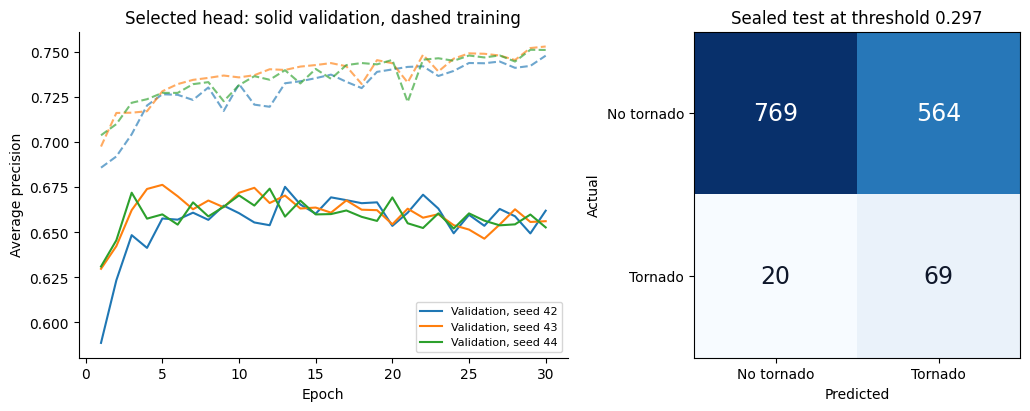

,case,filename,label,score_history
0,Highest-scoring false positive,test/2015/WRN_150408_003533_KJKL_1074913n_I1.nc,0,0.999848
1,Lowest-scoring false negative,test/2014/TOR_140518_235356_KUDX_511791_X0.nc,1,0.062176
2,Seeded correct positive,test/2015/TOR_150407_193102_KVWX_566994_G4.nc,1,0.999983


In [5]:
import numpy as np

curves = pd.read_csv(ROOT / "results/learning_curves.csv")
selected_curves = curves[curves.configuration == final["selected_configuration"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for seed, curve in selected_curves.groupby("seed"):
    line, = axes[0].plot(curve.epoch, curve.validation_average_precision, label=f"Validation, seed {seed}")
    axes[0].plot(curve.epoch, curve.train_average_precision, linestyle="--", color=line.get_color(), alpha=.65)
axes[0].set(xlabel="Epoch", ylabel="Average precision", title="Selected head: solid validation, dashed training")
axes[0].legend(fontsize=8)
axes[0].spines[["top", "right"]].set_visible(False)
selected_metrics = final["metrics"][final["selected_configuration"]]
confusion = np.array([[selected_metrics["tn"], selected_metrics["fp"]],
                      [selected_metrics["fn"], selected_metrics["tp"]]])
axes[1].imshow(confusion, cmap="Blues")
axes[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["No tornado", "Tornado"],
            yticklabels=["No tornado", "Tornado"], xlabel="Predicted", ylabel="Actual",
            title=f"Sealed test at threshold {selected_metrics['threshold']:.3f}")
for (row, col), count in np.ndenumerate(confusion):
    axes[1].text(col, row, str(count), ha="center", va="center", fontsize=17,
                 color="white" if count > confusion.max() / 2 else "#0f172a")
plt.show()

model = final["selected_configuration"]
score, predicted = f"score_{model}", f"prediction_{model}"
false_positives = predictions[(predictions.label == 0) & (predictions[predicted] == 1)]
false_negatives = predictions[(predictions.label == 1) & (predictions[predicted] == 0)]
true_positives = predictions[(predictions.label == 1) & (predictions[predicted] == 1)]
examples = pd.concat([
    false_positives.nlargest(1, score).assign(case="Highest-scoring false positive"),
    false_negatives.nsmallest(1, score).assign(case="Lowest-scoring false negative"),
    true_positives.sample(n=min(1, len(true_positives)), random_state=42).assign(case="Seeded correct positive"),
])
display(examples[["case", "filename", "label", score]].reset_index(drop=True))

## 3. The biggest lessons

1. **Better ranking did not mean fewer false alarms.** The selected head detected
   one additional positive clip while adding 288 false positives versus the
   original CNN at their separately locked thresholds. The paired storm-group
   95% bootstrap interval for its AP gain is **[-0.061, 0.155]**, including zero.
2. **A small temporal change was worth testing.** Two-scan averaging raised mean
   validation AP from 0.658 to 0.675 with the same 385 head parameters. A 24,705-
   parameter MLP reached 0.670 and was not selected under the declared rule.
3. **More hard-negative weight did not solve false positives.** Doubling weights
   for warning-category clips with label zero gave 0.656 mean validation AP,
   slightly below baseline. Warning-negative FPR was 0.530 versus 0.507 after
   reselecting thresholds for the same validation recall target. Small differences
   and seed variation do not establish a mechanism.
4. **Data identity mattered before modeling.** The first audit rejected 2,325
   warning clips because embedded event/episode IDs were legacy values. Corrected
   v1.1 catalog IDs, exact filenames, sites, and timestamps established grouping
   identity; labels and splits stayed fixed. The failed audit and final remap remain.
5. **Rare positives and correlated storms limit the conclusion.** Predicting no
   tornado gets 93.7% test accuracy while missing all 89 positive clips. There are
   only 10 test storm groups, and prevalence drops from 13.4% in validation to
   6.3% in test. AP changes across those splits are not a pure overfitting measure.

This is retrospective **current tornado detection on selected storm crops**.
It does not demonstrate advance forecasting or operational warning performance.
The checkpoint has no sample-level training list; weather-date overlap remains.
Class-weighted sigmoid scores are not calibrated tornado probabilities.

[RESULTS.md](RESULTS.md) has the full measured discussion;
[PROTOCOL.md](PROTOCOL.md) records the scientific design.


## 4. Complete implementation

All study code is below, organized into notebook cells by responsibility. The
`study_module` cell magic writes each cell into ignored `.study_runtime/` and
imports it. This keeps namespaces separate and lets integrity checks hash the
exact scientific source used in the original experiment. It does not depend on
standalone project scripts. The original feature extractor and training/evaluation
implementation are preserved byte for byte. The verifier and split generator
use the generated source paths.

The source cells are initially collapsed in compatible notebook viewers. Run
them in order. No data acquisition, model fitting, or holdout evaluation happens
when the implementations are loaded.


In [6]:
import hashlib
import importlib.util
import sys
from IPython.core.magic import register_cell_magic

RUNTIME = ROOT / ".study_runtime"
RUNTIME.mkdir(exist_ok=True)
notebook = read_json("tornet_study.ipynb")
SOURCE_HASHES = notebook["metadata"]["study_source_sha256"]
sys.path.insert(0, str(ROOT / "upstream"))
sys.path.insert(0, str(RUNTIME))

@register_cell_magic
def study_module(name, source):
    name = name.strip()
    if name not in SOURCE_HASHES:
        raise ValueError(f"Unknown study module: {name}")
    payload = (source.replace("\r\n", "\n").rstrip("\n") + "\n").encode("utf-8")
    if hashlib.sha256(payload).hexdigest() != SOURCE_HASHES[name]:
        raise ValueError(f"{name}: source differs from this recorded study. Use a new study for changes.")
    path = RUNTIME / f"{name}.py"
    if not path.exists() or path.read_bytes() != payload:
        path.write_bytes(payload)
    spec = importlib.util.spec_from_file_location(name, path)
    loaded = importlib.util.module_from_spec(spec)
    sys.modules[name] = loaded
    spec.loader.exec_module(loaded)
    loaded.ROOT = ROOT
    for attribute, folder in [("DATA", "data"), ("RESULTS", "results"), ("UPSTREAM", "upstream")]:
        if hasattr(loaded, attribute):
            setattr(loaded, attribute, ROOT / folder)
    globals()[name] = loaded
    print(f"Loaded {name}")


### Public input downloads

The complete implementation is in the following code cell.


In [7]:
%%study_module download_assets
"""Restore public inputs at their recorded revisions and SHA-256 hashes."""
from __future__ import annotations

import hashlib
import json
from pathlib import Path
import tempfile
from urllib.request import Request, urlopen

ROOT = Path(__file__).resolve().parent


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def download(url, target, expected_sha256):
    """Install only recorded bytes; preserve any existing mismatched file."""
    target = Path(target)
    if target.exists():
        if sha256(target) != expected_sha256:
            raise ValueError(f"SHA-256 mismatch: {target}. Move this file aside before retrying.")
        print(f"Verified {target.name}")
        return target
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        print(f"Downloading {target.name}", flush=True)
        request = Request(url, headers={"User-Agent": "tornet-transfer-learning"})
        with urlopen(request, timeout=60) as response, tempfile.NamedTemporaryFile(
            dir=target.parent, prefix=f".{target.name}.", suffix=".part", delete=False
        ) as handle:
            temporary = Path(handle.name)
            for block in iter(lambda: response.read(1024 * 1024), b""):
                handle.write(block)
        if sha256(temporary) != expected_sha256:
            raise ValueError(f"Downloaded SHA-256 mismatch: {target.name}; input was not installed.")
        temporary.replace(target)
    finally:
        if temporary is not None:
            temporary.unlink(missing_ok=True)
    print(f"Verified {target.name}")
    return target


def ensure_asset(name):
    config = json.loads((ROOT / "planned_config.json").read_text(encoding="utf-8"))
    if name == "checkpoint":
        model = config["model"]
        provenance = json.loads((ROOT / "data/feature_provenance.json").read_text(encoding="utf-8"))
        url = f"https://huggingface.co/{model['repository']}/resolve/{model['revision']}/{model['filename']}"
        return download(url, ROOT / "probe" / model["filename"], provenance["checkpoint_sha256"])
    if name == "catalog":
        census = json.loads((ROOT / "design/dataset_census.json").read_text(encoding="utf-8"))
        return download(config["data"]["catalog_source"], ROOT / "design/catalog.csv", census["catalog_sha256"])
    raise ValueError(f"Unknown asset: {name}")


Loaded download_assets


### Source-training proximity exclusion

The complete implementation is in the following code cell.


In [8]:
%%study_module source_independence
"""Audit TorNet sample proximity to the pretrained model's source training data.

The TorNet paper, Section 3.1, reports removing training samples within
30 minutes and 0.25 degrees of latitude/longitude of any test sample:
https://arxiv.org/html/2401.16437v1#S3.SS1

This audit reapplies that documented criterion to the downloaded catalog,
using nominal terminal ``end_time`` timestamps and catalog chip locations.
It returns evidence so callers can exclude evaluation candidates rather than
changing the pretrained model's training data. It does not prove independence
of entire weather systems or establish which files the checkpoint saw.
"""

from __future__ import annotations

import numpy as np
import pandas as pd


_REQUIRED = ("end_time", "lat", "lon", "filename", "episode_id", "event_id")
_EVIDENCE_COLUMNS = (
    "selected_position", "selected_index", "selected_filename",
    "selected_episode_id", "selected_event_id", "selected_end_time",
    "selected_lat", "selected_lon", "source_train_position",
    "source_train_index", "source_train_filename", "source_train_episode_id",
    "source_train_event_id", "source_train_end_time", "source_train_lat",
    "source_train_lon", "time_difference_seconds", "latitude_difference_degrees",
    "longitude_difference_degrees",
)


def _coordinates_and_times(rows: pd.DataFrame, name: str):
    missing = set(_REQUIRED) - set(rows.columns)
    if missing:
        raise ValueError(f"{name} is missing required columns: {sorted(missing)}")
    times = pd.to_datetime(rows["end_time"], utc=True, errors="raise", format="mixed")
    if times.isna().any():
        raise ValueError(f"{name} contains missing end_time values")
    # Explicit nanosecond conversion also supports pandas datetime units other
    # than ns, while UTC conversion makes aware and naive catalog times agree.
    nanoseconds = times.to_numpy(dtype="datetime64[ns]").astype(np.int64)
    latitudes = pd.to_numeric(rows["lat"], errors="raise").to_numpy(dtype=float)
    longitudes = pd.to_numeric(rows["lon"], errors="raise").to_numpy(dtype=float)
    if not np.isfinite(latitudes).all() or not np.isfinite(longitudes).all():
        raise ValueError(f"{name} contains missing or non-finite coordinates")
    return times, nanoseconds, latitudes, longitudes


def proximity_exclusions(
    selected: pd.DataFrame,
    source_train: pd.DataFrame,
    *,
    minutes: float = 30.0,
    coordinate_tolerance_degrees: float = 0.25,
) -> tuple[np.ndarray, pd.DataFrame]:
    """Return a positional exclusion mask and every matching training pair.

    A pair matches only when all three inclusive conditions hold:
    ``abs(end_time difference) <= minutes`` and each absolute latitude and
    longitude difference is at most ``coordinate_tolerance_degrees``.

    ``mask[i]`` applies to ``selected.iloc[i]``; input index labels need not be
    consecutive or unique. Evidence includes both positions and original index
    labels. Source training rows are searched by sorted time, so comparisons
    are limited to the temporal neighborhood rather than the whole catalog.
    Neither input is mutated, and no files or network resources are accessed.
    Missing times or coordinates raise an error rather than silently treating
    an unauditable row as independent.
    """
    if not np.isfinite(minutes) or minutes < 0:
        raise ValueError("minutes must be finite and non-negative")
    if (not np.isfinite(coordinate_tolerance_degrees)
            or coordinate_tolerance_degrees < 0):
        raise ValueError("coordinate_tolerance_degrees must be finite and non-negative")
    window_ns = int(pd.Timedelta(minutes=minutes).value)
    selected_times, selected_ns, selected_lat, selected_lon = _coordinates_and_times(
        selected, "selected"
    )
    train_times, train_ns, train_lat, train_lon = _coordinates_and_times(
        source_train, "source_train"
    )
    mask = np.zeros(len(selected), dtype=bool)
    evidence = []
    order = np.argsort(train_ns, kind="stable")
    ordered_times = train_ns[order]
    for position, timestamp in enumerate(selected_ns):
        left = np.searchsorted(ordered_times, int(timestamp) - window_ns, side="left")
        right = np.searchsorted(ordered_times, int(timestamp) + window_ns, side="right")
        candidates = order[left:right]
        latitude_differences = np.abs(train_lat[candidates] - selected_lat[position])
        longitude_differences = np.abs(train_lon[candidates] - selected_lon[position])
        nearby = candidates[
            (latitude_differences <= coordinate_tolerance_degrees)
            & (longitude_differences <= coordinate_tolerance_degrees)
        ]
        if not len(nearby):
            continue
        mask[position] = True
        selected_row = selected.iloc[position]
        for train_position in nearby:
            train_row = source_train.iloc[train_position]
            evidence.append({
                "selected_position": position,
                "selected_index": selected.index[position],
                "selected_filename": selected_row["filename"],
                "selected_episode_id": selected_row["episode_id"],
                "selected_event_id": selected_row["event_id"],
                "selected_end_time": selected_times.iloc[position].isoformat(),
                "selected_lat": selected_lat[position],
                "selected_lon": selected_lon[position],
                "source_train_position": int(train_position),
                "source_train_index": source_train.index[train_position],
                "source_train_filename": train_row["filename"],
                "source_train_episode_id": train_row["episode_id"],
                "source_train_event_id": train_row["event_id"],
                "source_train_end_time": train_times.iloc[train_position].isoformat(),
                "source_train_lat": train_lat[train_position],
                "source_train_lon": train_lon[train_position],
                "time_difference_seconds": abs(int(train_ns[train_position]) - int(timestamp)) / 1e9,
                "latitude_difference_degrees": abs(train_lat[train_position] - selected_lat[position]),
                "longitude_difference_degrees": abs(train_lon[train_position] - selected_lon[position]),
            })
    return mask, pd.DataFrame(evidence, columns=_EVIDENCE_COLUMNS)


Loaded source_independence


### Metadata-only grouped split design

The complete implementation is in the following code cell.


In [9]:
%%study_module design_study
"""Build a TorNet study manifest using catalog metadata, before any training.

Source categories are sampling strata, not per-frame target labels. Radar-label
and timestamp checks must still pass before the experiment can be executed.
"""
from __future__ import annotations

import hashlib
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
from source_independence import proximity_exclusions

ROOT = Path(__file__).resolve().parent
SPLITS = ("train", "val", "test")
CATEGORIES = ("NUL", "TOR", "WRN")


def window_dates(start, end):
    return pd.date_range(pd.Timestamp(start).normalize(),
                         pd.Timestamp(end).normalize(), freq="D").strftime("%Y-%m-%d")


def group_storm_days(catalog: pd.DataFrame) -> np.ndarray:
    """Keep entire episodes and every shared input-window UTC date together."""
    episodes = sorted(catalog.episode_id.astype(str).unique())
    parent = {episode: episode for episode in episodes}

    def find(episode):
        while parent[episode] != episode:
            parent[episode] = parent[parent[episode]]
            episode = parent[episode]
        return episode

    def union(left, right):
        left, right = find(left), find(right)
        if left != right:
            parent[max(left, right)] = min(left, right)

    date_owner = {}
    for row in catalog.itertuples():
        episode = str(row.episode_id)
        for day in window_dates(row.start_time, row.end_time):
            if day in date_owner:
                union(episode, date_owner[day])
            else:
                date_owner[day] = episode
    return np.asarray([find(str(episode)) for episode in catalog.episode_id])


def stratify_groups(selected: pd.DataFrame, config: dict):
    """Choose the lowest declared category-count imbalance among fixed draws.

    Objective: equally weighted mean squared relative category-count and
    year-count deviation from targets. No radar arrays, target labels or model
    scores are read. Ties retain the first draw. This is dataset preparation.
    """
    cfg = config["data"]
    table = pd.crosstab(selected.storm_group, selected.category).reindex(
        columns=CATEGORIES, fill_value=0)
    counts = table.to_numpy()
    year_counts = pd.crosstab(selected.storm_group, selected.source_year).reindex(
        index=table.index, fill_value=0).to_numpy()
    sizes = cfg["split_group_counts"]
    if sum(sizes) != len(table):
        raise ValueError("Group count changed; revise the protocol before training.")
    target = np.asarray(cfg["split_target_fractions"])[:, None] * counts.sum(axis=0)
    year_target = np.asarray(cfg["split_target_fractions"])[:, None] * year_counts.sum(axis=0)
    rng = np.random.default_rng(config["split_seed"])
    best_score, best_assignment, best_trial = float("inf"), None, None
    valid = 0
    for trial in range(cfg["split_search_candidates"]):
        order = rng.permutation(len(table))
        assignment = np.empty(len(table), dtype=np.int64)
        cursor = 0
        for split_index, size in enumerate(sizes):
            assignment[order[cursor:cursor + size]] = split_index
            cursor += size
        split_counts = np.asarray([counts[assignment == i].sum(axis=0) for i in range(3)])
        tor_groups = [np.count_nonzero(counts[assignment == i, 1]) for i in range(3)]
        wrn_groups = [np.count_nonzero(counts[assignment == i, 2]) for i in (1, 2)]
        if min(tor_groups) < cfg["split_min_tornado_category_groups"]:
            continue
        if min(wrn_groups) < cfg["split_min_warning_category_eval_groups"]:
            continue
        if split_counts[1:, 1].min() < 40 or (split_counts == 0).any():
            continue
        valid += 1
        split_years = np.asarray([year_counts[assignment == i].sum(axis=0) for i in range(3)])
        score = float(0.5 * np.square((split_counts - target) / target).mean()
                      + 0.5 * np.square((split_years - year_target) / year_target).mean())
        if score < best_score:
            best_score, best_assignment, best_trial = score, assignment.copy(), trial
    if best_assignment is None:
        raise ValueError("No admissible metadata split. Revise before training.")
    mapping = dict(zip(table.index, (SPLITS[i] for i in best_assignment)))
    details = {"candidate_draws": cfg["split_search_candidates"],
               "admissible_draws": valid, "chosen_zero_based_draw": best_trial,
               "stratification_objective": best_score,
               "objective": "0.5*category mean squared relative deviation +0.5*year mean squared relative deviation from 60/20/20 targets"}
    return selected.storm_group.map(mapping), details


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def build_plan():
    config_path = ROOT / "planned_config.json"
    config = json.loads(config_path.read_text(encoding="utf-8-sig"))
    catalog_path = ROOT / "design/catalog.csv"
    data = pd.read_csv(catalog_path)
    years = pd.to_datetime(data.end_time).dt.year
    selected = data[(data["type"] == config["data"]["source_partition"])
                    & years.isin(config["data"]["years"])].copy()
    source_train = data[data["type"] == "train"]
    overlap = (selected.episode_id.isin(source_train.episode_id)
               | selected.event_id.isin(source_train.event_id))
    excluded = selected[overlap].copy()
    source_pool_size = len(selected)
    selected = selected[~overlap].copy()
    proximity_mask, proximity_evidence = proximity_exclusions(
        selected, source_train,
        minutes=config["data"]["source_train_proximity_minutes"],
        coordinate_tolerance_degrees=config["data"]["source_train_proximity_coordinate_degrees"])
    proximity_excluded = selected[proximity_mask].copy()
    selected = selected[~proximity_mask].copy()
    excluded.to_csv(ROOT / "design/source_episode_overlap.csv", index=False, lineterminator="\n")
    proximity_evidence.to_csv(ROOT / "design/source_proximity_overlap.csv", index=False, lineterminator="\n")
    assert not set(selected.episode_id) & set(source_train.episode_id)
    assert not set(selected.event_id) & set(source_train.event_id)
    selected = selected.sort_values("filename").reset_index(drop=True)
    selected["source_year"] = pd.to_datetime(selected.end_time).dt.year
    selected["storm_group"] = group_storm_days(selected)
    selected["study_split"], split_details = stratify_groups(selected, config)
    assert selected.filename.is_unique
    assert selected.study_split.notna().all()

    for left, right in (("train", "val"), ("train", "test"), ("val", "test")):
        l = selected[selected.study_split == left]
        r = selected[selected.study_split == right]
        assert not set(l.episode_id) & set(r.episode_id)
        assert not set(l.storm_group) & set(r.storm_group)
        l_dates = {day for row in l.itertuples() for day in window_dates(row.start_time, row.end_time)}
        r_dates = {day for row in r.itertuples() for day in window_dates(row.start_time, row.end_time)}
        assert not l_dates & r_dates

    output = ROOT / "design/planned_manifest.csv"
    selected.to_csv(output, index=False, lineterminator="\n")
    summary = []
    for split in SPLITS:
        section = selected[selected.study_split == split]
        item = {"split": split, "chips": len(section),
                "episodes": int(section.episode_id.nunique()),
                "storm_day_groups": int(section.storm_group.nunique()),
                "largest_group_chips": int(section.groupby("storm_group").size().max()),
                "years": {str(year): len(part) for year, part in section.groupby("source_year")},
                "categories": {}}
        for category, part in section.groupby("category"):
            item["categories"][category] = {"chips": len(part),
                "episodes": int(part.episode_id.nunique()),
                "storm_day_groups": int(part.storm_group.nunique())}
        summary.append(item)

    weights = ROOT / "probe/tornado_detector_baseline.keras"
    census = {"dataset_version": "1.1", "catalog_rows": len(data),
              "selected_years": config["data"]["years"],
              "source_partition": "authors official test", "samples": len(selected),
              "source_pool_before_overlap_filter": source_pool_size,
              "excluded_source_train_overlap_clips": len(excluded),
              "excluded_episode_ids": sorted(excluded.episode_id.unique().tolist()),
              "excluded_source_train_proximity_clips": len(proximity_excluded),
              "proximity_evidence_file": "source_proximity_overlap.csv",
              "episodes": int(selected.episode_id.nunique()),
              "storm_day_groups": int(selected.storm_group.nunique()),
              "splits": summary, "split_search": split_details,
              "catalog_sha256": sha256(catalog_path),
              "manifest_sha256": sha256(output), "config_sha256": sha256(config_path),
              "design_script_sha256": sha256(Path(__file__).resolve()),
              "proximity_script_sha256": sha256(Path(__file__).with_name("source_independence.py")),
              "checkpoint_sha256": sha256(weights) if weights.exists() else None,
              "design_environment": {"python": platform.python_version(),
                  "numpy": np.__version__, "pandas": pd.__version__},
              "label_note": "TOR is a category; actual terminal-frame labels and positive group counts still require NetCDF audit.",
              "partition_basis": "Authors documented holdout protocol plus episode/event/proximity exclusion; checkpoint has no embedded training provenance. Other episodes on same weather days may have been seen during pretraining.",
              "grouping": "Complete episodes joined when they share any UTC date from start_time through end_time.",
              "status": "Catalog and split verified. No new training or final test inference performed."}
    (ROOT / "design/dataset_census.json").write_text(json.dumps(census, indent=2) + "\n", encoding="utf-8")
    print(json.dumps(census, indent=2))
    return output


if __name__ == "__main__":
    build_plan()


Loaded design_study


### Radar acquisition, extraction, and label audit

The complete implementation is in the following code cell.


In [10]:
%%study_module data_pipeline
"""Download checksum-verified TorNet archives, extract selected cases, audit labels.

This stage never loads a model or computes predictions. Study splits remain fixed.
"""
from __future__ import annotations

import argparse
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
import hashlib
import json
import os
from pathlib import Path, PurePosixPath
import re
import shutil
import tarfile
import time

import pandas as pd
import requests

ROOT = Path(__file__).resolve().parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
ARCHIVES = {
    2014: {"record": 12637032, "filename": "tornet_2014.tar.gz", "size": 15066513529,
           "md5": "db8bbdf9939153209f7b3d7cfe60dd7d"},
    2015: {"record": 12655151, "filename": "tornet_2015.tar.gz", "size": 17395624045,
           "md5": "7251feab3c571c71fcca8745d8431c7d"},
}
VARIABLES = ["DBZ", "VEL", "KDP", "RHOHV", "ZDR", "WIDTH"]


def utc_now():
    return datetime.now(timezone.utc).isoformat()


def digest(path, algorithm="sha256"):
    h = hashlib.new(algorithm)
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def write_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")
    temp.replace(path)


def download_archive(year, connections=8):
    meta = ARCHIVES[year]
    out = DATA / "archives" / meta["filename"]
    out.parent.mkdir(parents=True, exist_ok=True)
    verified = out.with_suffix(out.suffix + ".verified.json")
    if out.exists() and out.stat().st_size == meta["size"] and verified.exists():
        prior = json.loads(verified.read_text())
        if prior["md5"] == meta["md5"] and prior.get("mtime_ns") == out.stat().st_mtime_ns:
            print(f"{year}: previously checksum-verified archive reused", flush=True)
            return out
        actual = digest(out, "md5")
        if actual != meta["md5"]:
            raise RuntimeError(f"Previously downloaded archive was modified: {out}")
        prior.update({"md5": actual, "verified_at": utc_now(), "mtime_ns": out.stat().st_mtime_ns})
        write_json(verified, prior)
        return out
    api = f"https://zenodo.org/api/records/{meta['record']}"
    response = requests.get(api, timeout=60)
    response.raise_for_status()
    entry = next(f for f in response.json()["files"] if f["key"] == meta["filename"])
    assert entry["size"] == meta["size"] and entry["checksum"] == "md5:" + meta["md5"]
    write_json(out.parent / f"{year}_zenodo_metadata.json", response.json())
    url = f"https://zenodo.org/records/{meta['record']}/files/{meta['filename']}?download=1"
    part = out.with_suffix(out.suffix + ".part")
    started = time.monotonic()
    prefix_size = part.stat().st_size if part.exists() else 0
    chunk_root = out.parent / (meta["filename"] + ".chunks")
    chunk_root.mkdir(exist_ok=True)
    plan_path = chunk_root / "plan.json"
    if plan_path.exists():
        plan = json.loads(plan_path.read_text())
        prefix_size = plan["prefix_size"]
    else:
        plan = {"prefix_size": prefix_size, "chunk_size": 64 * 1024 * 1024,
                "official_size": meta["size"]}
        write_json(plan_path, plan)
    ranges = [(start, min(meta["size"] - 1, start + plan["chunk_size"] - 1))
              for start in range(prefix_size, meta["size"], plan["chunk_size"])]

    def fetch_chunk(bounds):
        start, end = bounds
        target = chunk_root / f"{start:012d}-{end:012d}.chunk"
        expected = end - start + 1
        if target.exists() and target.stat().st_size == expected:
            return target
        temporary = target.with_suffix(".chunk.part")
        attempt = 0
        while attempt < 10:
            offset = temporary.stat().st_size if temporary.exists() else 0
            if offset == expected:
                temporary.replace(target)
                return target
            try:
                # Zenodo large-response streams were strongly throttled in the actual
                # download pilot. Eight-MiB requests retain exact resumability while
                # staying below the service's documented response rate limit.
                request_end = min(end, start + offset + 8 * 1024 * 1024 - 1)
                with requests.get(url, headers={"Range": f"bytes={start + offset}-{request_end}"},
                                  stream=True, timeout=(60, 180)) as response:
                    response.raise_for_status()
                    content_range = response.headers.get("Content-Range", "")
                    if response.status_code != 206 or content_range != f"bytes {start + offset}-{request_end}/{meta['size']}":
                        raise RuntimeError(f"Incorrect range response: {response.status_code}, {content_range}")
                    with temporary.open("ab" if offset else "wb") as f:
                        for chunk in response.iter_content(chunk_size=1024 * 1024):
                            if chunk:
                                f.write(chunk)
                                offset += len(chunk)
                                if offset > expected:
                                    raise RuntimeError("Range exceeded expected size")
                if temporary.stat().st_size != request_end - start + 1:
                    raise RuntimeError("Truncated range response")
                if temporary.stat().st_size == expected:
                    temporary.replace(target)
                    return target
                attempt = 0
            except (requests.RequestException, RuntimeError) as exc:
                print(f"{year}: range {start}-{end} attempt {attempt + 1}: {exc}", flush=True)
                if attempt == 9:
                    raise
                time.sleep(min(5 * (attempt + 1), 30))
                attempt += 1
        raise RuntimeError("Failed range")

    print(f"{year}: downloading {len(ranges)} ranges with {connections} connections; "
          f"reusing {prefix_size / 1e6:.1f} MB prefix", flush=True)
    paths = []
    completed_bytes = prefix_size
    last_report = 0
    from concurrent.futures import as_completed
    with ThreadPoolExecutor(max_workers=connections) as executor:
        futures = {executor.submit(fetch_chunk, bounds): bounds for bounds in ranges}
        for future in as_completed(futures):
            path = future.result()
            paths.append(path)
            completed_bytes += path.stat().st_size
            now = time.monotonic()
            if now - last_report > 30:
                print(f"{year}: completed {completed_bytes / 1e9:.2f}/{meta['size'] / 1e9:.2f} GB "
                      f"({100 * completed_bytes / meta['size']:.1f}%), elapsed {now - started:.0f}s", flush=True)
                last_report = now
    # Assembly is resumable: keep the original prefix and truncate any partial assembly.
    with part.open("r+b" if part.exists() else "wb") as output:
        output.truncate(prefix_size)
        output.seek(prefix_size)
        for path in sorted(paths):
            with path.open("rb") as chunk:
                shutil.copyfileobj(chunk, output, 8 * 1024 * 1024)
    assert part.stat().st_size == meta["size"], "Truncated archive"
    print(f"{year}: checking full archive MD5", flush=True)
    actual = digest(part, "md5")
    if actual != meta["md5"]:
        raise RuntimeError(f"Archive checksum mismatch: {actual}, expected {meta['md5']}")
    part.replace(out)
    write_json(verified, {"year": year, "md5": actual, "official_size": meta["size"],
                         "verified_at": utc_now(), "source": url,
                         "mtime_ns": out.stat().st_mtime_ns,
                         "download_elapsed_seconds": time.monotonic() - started})
    # Remove only exact chunk files under the checked task-owned directory.
    chunk_root = chunk_root.resolve()
    if not chunk_root.is_relative_to(DATA.resolve()):
        raise RuntimeError("Chunk cleanup target escaped the task data directory")
    for path in paths:
        path.unlink()
    plan_path.unlink()
    chunk_root.rmdir()
    print(f"{year}: archive checksum passed", flush=True)
    return out


def extract_selected(archive, year, manifest):
    archive = Path(archive)
    receipt_path = archive.with_suffix(archive.suffix + ".verified.json")
    if not receipt_path.exists():
        raise RuntimeError("Selective extraction requires an official archive checksum receipt")
    proof = json.loads(receipt_path.read_text())
    if proof["md5"] != ARCHIVES[year]["md5"] or archive.stat().st_size != ARCHIVES[year]["size"]:
        raise RuntimeError("Archive receipt does not match official metadata")
    if proof.get("mtime_ns") != archive.stat().st_mtime_ns:
        actual = digest(archive, "md5")
        if actual != ARCHIVES[year]["md5"]:
            raise RuntimeError("Archive changed after checksum verification")
        proof.update({"mtime_ns": archive.stat().st_mtime_ns, "verified_at": utc_now()})
        write_json(receipt_path, proof)
    selected = set(manifest.loc[manifest.source_year == year, "filename"])
    extracted = set()
    root = (DATA / "netcdf").resolve()
    root.mkdir(parents=True, exist_ok=True)
    started = time.monotonic()
    last_report = started
    with tarfile.open(archive, "r|gz") as tar:
        for member in tar:
            name = member.name.removeprefix("./")
            # Archives may have one named root directory; only the exact test path is used.
            pieces = PurePosixPath(name).parts
            if "test" not in pieces:
                continue
            name = str(PurePosixPath(*pieces[pieces.index("test"):]))
            if name not in selected:
                continue
            if not member.isfile() or member.issym() or member.islnk():
                raise RuntimeError(f"Selected member is not a regular file: {member.name}")
            target = (root / Path(*PurePosixPath(name).parts)).resolve()
            if not target.is_relative_to(root):
                raise RuntimeError(f"Unsafe archive member: {member.name}")
            prior_good = False
            receipt_path = target.with_suffix(".nc.sha256")
            if target.exists() and target.stat().st_size == member.size and receipt_path.exists():
                prior_good = digest(target) == receipt_path.read_text().strip()
            if not prior_good:
                target.parent.mkdir(parents=True, exist_ok=True)
                stream = tar.extractfile(member)
                if stream is None:
                    raise RuntimeError(f"Cannot read selected member: {member.name}")
                temporary = target.with_suffix(".nc.tmp")
                with temporary.open("wb") as f:
                    shutil.copyfileobj(stream, f, 1024 * 1024)
                assert temporary.stat().st_size == member.size
                temporary.replace(target)
                receipt_path.write_text(digest(target), encoding="utf-8")
            extracted.add(name)
            if len(extracted) == 1:
                print(f"{year}: first extracted sample {target}", flush=True)
                write_json(DATA / "first_sample.json", {"path": str(target), "filename": name,
                           "year": year, "created_at": utc_now()})
            now = time.monotonic()
            if now - last_report > 30:
                print(f"{year}: selected extraction {len(extracted)}/{len(selected)}, "
                      f"elapsed {now - started:.0f}s", flush=True)
                last_report = now
    missing = sorted(selected - extracted)
    if missing:
        raise RuntimeError(f"Archive missing {len(missing)} selected names: {missing[:5]}")
    print(f"{year}: extracted {len(extracted)} selected files", flush=True)
    return {"year": year, "files": len(extracted), "elapsed_seconds": time.monotonic() - started,
            "archive_md5": ARCHIVES[year]["md5"],
            "planned_manifest_sha256": digest(ROOT / "design" / "planned_manifest.csv")}


def record_extractions(records):
    """Merge independently completed years into one durable extraction ledger."""
    ledger = DATA / "extraction_log.json"
    prior = json.loads(ledger.read_text()) if ledger.exists() else []
    merged = {int(record["year"]): record for record in prior}
    merged.update({int(record["year"]): record for record in records})
    write_json(ledger, [merged[year] for year in sorted(merged)])


def audit_sample(row):
    import numpy as np
    import xarray as xr

    path = DATA / "netcdf" / Path(*PurePosixPath(row["filename"]).parts)
    out = {**row, "path": str(path.resolve()), "data_path": str(path.resolve()),
           "status": "valid", "exclusion_reason": ""}
    issues = []
    missing_fields = []
    try:
        with xr.open_dataset(path) as ds:
            times = np.asarray(ds.time.values).astype("datetime64[ns]")
            numeric = times.astype("int64")
            if len(times) < 2 or np.isnat(times).any() or (np.diff(numeric) <= 0).any():
                issues.append("timestamps_missing_or_not_strictly_ordered")
            gap = float((numeric[-1] - numeric[-2]) / 1e9) if len(times) >= 2 else -1
            if not 180 <= gap <= 420:
                issues.append("previous_to_current_gap_outside_3_to_7_minutes")
            labels = np.asarray(ds["frame_labels"].values)
            if labels.shape != (len(times),) or not np.isin(labels, [0, 1]).all():
                issues.append("frame_labels_missing_or_not_binary")
            for var in VARIABLES:
                if var not in ds or ds[var].shape != (len(times), 120, 240, 2):
                    issues.append("invalid_shape_" + var)
                    continue
                value = np.asarray(ds[var].values[-2:])
                if np.isinf(value).any():
                    issues.append("infinite_radar_values_" + var)
                # Missing values are supported by the authors' FillNaNs layer.
                # Even fully missing fields are retained, with an explicit audit.
                if not np.isfinite(value[-1]).any():
                    missing_fields.append(var + "_current")
                if not np.isfinite(value[-2]).any():
                    missing_fields.append(var + "_previous")
            mask_shape = tuple(ds["range_folded_mask"].shape)
            if mask_shape != (len(times), 120, 240, 2):
                issues.append("invalid_range_folded_mask_shape")
            for limit in ["azimuth_limits", "range_limits"]:
                a = np.asarray(ds[limit].values)
                if a.shape != (2,) or not np.isfinite(a).all():
                    issues.append("invalid_" + limit)
            category = str(ds.attrs.get("category", ""))
            if category != row["category"]:
                issues.append("netcdf_catalog_category_mismatch")
            site_match = str(ds.attrs.get("site_name", "")) == row["site_name"]
            if not site_match:
                issues.append("netcdf_catalog_site_mismatch")
            terminal_time_match = pd.Timestamp(row["end_time"]) == pd.Timestamp(times[-1])
            if not terminal_time_match:
                issues.append("netcdf_catalog_terminal_time_mismatch")
            event = int(ds.attrs.get("event_id", -999))
            episode = int(ds.attrs.get("episode_id", -999))
            event_mismatch = event != int(row["event_id"])
            episode_mismatch = episode != int(row["episode_id"])
            correction_applied = False
            # Upstream v1.1 documents corrected warning IDs. Official archives retain
            # their old attrs, while exact filenames match the corrected catalog IDs.
            # These attrs are provenance only; target labels and radar arrays stay raw.
            if category == "WRN" and (event_mismatch or episode_mismatch):
                token = re.search(r"_([0-9]+)n_", Path(row["filename"]).name)
                canonical_filename = token is not None and int(token.group(1)) == int(row["event_id"])
                if canonical_filename and category == row["category"] and site_match and terminal_time_match:
                    correction_applied = True
                else:
                    issues.append("warning_corrected_catalog_identity_not_confirmed")
            else:
                if event_mismatch:
                    issues.append("netcdf_catalog_event_mismatch")
                if episode_mismatch:
                    issues.append("netcdf_catalog_episode_mismatch")
            label = int(labels[-1])
            out.update({"label": label, "previous_label": int(labels[-2]), "gap_seconds": gap,
                        "frame_count": len(times), "current_time": str(times[-1]),
                        "previous_time": str(times[-2]), "stored_terminal_vs_ef_mismatch":
                        label != int(float(ds.attrs.get("ef_number", -1)) >= 0),
                        "input_window_start_time": str(times[0]),
                        "input_window_end_time": str(times[-1]),
                        "data_sha256": digest(path),
                        "nc_event_id": event, "nc_episode_id": episode,
                        "native_event_mismatch": event_mismatch,
                        "native_episode_mismatch": episode_mismatch,
                        "catalog_id_correction_applied": correction_applied,
                        "catalog_terminal_time_match": terminal_time_match,
                        "all_missing_variable_frames": json.dumps(missing_fields),
                        "all_missing_variable_frame_count": len(missing_fields),
                        "current_frame_index": len(times) - 1, "previous_frame_index": len(times) - 2,
                        "netcdf_bytes": path.stat().st_size})
    except Exception as exc:
        issues.append(f"read_error:{type(exc).__name__}:{exc}")
    if issues:
        out["status"] = "excluded"
        out["exclusion_reason"] = "|".join(issues)
    return out


def audit_data(manifest, workers=4):
    started = time.monotonic()
    rows = manifest.to_dict("records")
    outputs = []
    with ThreadPoolExecutor(max_workers=workers) as executor:
        for i, result in enumerate(executor.map(audit_sample, rows), 1):
            outputs.append(result)
            if i % 250 == 0:
                print(f"QA: {i}/{len(rows)} clips audited", flush=True)
    all_rows = pd.DataFrame(outputs)
    valid = all_rows[all_rows.status == "valid"].copy()
    invalid = all_rows[all_rows.status != "valid"].copy()
    for column in ["label", "previous_label", "frame_count", "current_frame_index", "previous_frame_index",
                   "all_missing_variable_frame_count"]:
        valid[column] = valid[column].astype("int64")
    expected_metadata = manifest.loc[manifest.filename.isin(valid.filename)].reset_index(drop=True)
    pd.testing.assert_frame_equal(valid[manifest.columns].reset_index(drop=True), expected_metadata,
                                  check_dtype=True, check_exact=True)
    RESULTS.mkdir(parents=True, exist_ok=True)
    DATA.mkdir(parents=True, exist_ok=True)
    invalid.to_csv(DATA / "excluded_manifest.csv", index=False)
    valid.to_csv(DATA / "runtime_manifest.csv", index=False)
    census = {}
    failures = []
    if not valid.filename.is_unique:
        failures.append("Duplicate filenames in runtime manifest")
    for split in ["train", "val", "test"]:
        sub = valid[valid.study_split == split]
        positives = sub[sub.label == 1]
        negatives = sub[sub.label == 0]
        warnings = negatives[negatives.category == "WRN"]
        census[split] = {"samples": len(sub), "positive_samples": len(positives),
                        "negative_samples": len(negatives), "storm_groups": sub.storm_group.nunique(),
                        "positive_storm_groups": positives.storm_group.nunique(),
                        "warning_negative_samples": len(warnings),
                        "warning_negative_storm_groups": warnings.storm_group.nunique(),
                        "categories": sub.category.value_counts().to_dict()}
        if not len(positives) or not len(negatives):
            failures.append(split + " missing a label class")
        if split in ["val", "test"]:
            if len(positives) < 40 or positives.storm_group.nunique() < 8:
                failures.append(split + " below positive sample/group minimum")
            if warnings.storm_group.nunique() < 3:
                failures.append(split + " below warning-negative group minimum")
    # Recheck isolation using actual NetCDF times rather than catalog approximations.
    isolation = {"episode_overlap_pairs": [], "event_overlap_pairs": [], "utc_date_overlap_pairs": []}
    from itertools import combinations
    for left, right in combinations(["train", "val", "test"], 2):
        a = valid[valid.study_split == left]
        b = valid[valid.study_split == right]
        for column, key in [("episode_id", "episode_overlap_pairs"), ("event_id", "event_overlap_pairs")]:
            overlap = set(a[column]) & set(b[column])
            if overlap:
                isolation[key].append({"splits": [left, right], "ids": sorted(int(x) for x in overlap)})
                failures.append(f"{left}/{right} share {column}")
        def window_dates(sub):
            dates = set()
            for _, sample in sub.iterrows():
                dates.update(d.date().isoformat() for d in pd.date_range(
                    pd.Timestamp(sample.input_window_start_time).normalize(),
                    pd.Timestamp(sample.input_window_end_time).normalize(), freq="D"))
            return dates
        overlap = window_dates(a) & window_dates(b)
        if overlap:
            isolation["utc_date_overlap_pairs"].append({"splits": [left, right], "dates": sorted(overlap)})
            failures.append(f"{left}/{right} share actual input-window UTC dates")
    source_catalog = pd.read_csv(ROOT / "design" / "catalog.csv", parse_dates=["end_time"])
    source_train_dates = set(source_catalog.loc[source_catalog.type == "train", "end_time"].dt.date)
    selected_terminal_dates = pd.to_datetime(manifest.end_time).dt.date
    pretraining_weather_overlap = {
        "basis": "Catalog terminal UTC dates only; calendar-date overlap is not sample or necessarily weather-system overlap",
        "selected_clips_on_source_train_dates": int(selected_terminal_dates.isin(source_train_dates).sum()),
        "selected_clips": len(manifest), "shared_terminal_dates": len(set(selected_terminal_dates) & source_train_dates),
        "selected_terminal_dates": selected_terminal_dates.nunique(),
        "implication": "Do not claim all frozen-backbone weather environments are unseen"}
    from collections import Counter
    missingness_by_category = {}
    for category in ["NUL", "TOR", "WRN"]:
        sub = valid[valid.category == category]
        missingness_by_category[category] = {
            "samples": len(sub), "clips_with_any_all_missing_variable_frame":
                int((sub.all_missing_variable_frame_count > 0).sum()),
            "all_missing_variable_frame_counts": dict(Counter(
                flag for flags in sub.all_missing_variable_frames for flag in json.loads(flags)))}
    corrected = valid[valid.catalog_id_correction_applied]
    mapping_columns = ["filename", "category", "study_split", "storm_group", "episode_id", "event_id",
                       "nc_episode_id", "nc_event_id", "label", "previous_label", "current_time",
                       "previous_time", "catalog_terminal_time_match", "native_event_mismatch",
                       "native_episode_mismatch"]
    mapping = corrected[mapping_columns].rename(columns={"episode_id": "catalog_episode_id",
                                                         "event_id": "catalog_event_id"})
    mapping_path = DATA / "warning_metadata_remap.csv"
    mapping_tmp = mapping_path.with_suffix(".csv.tmp")
    mapping.to_csv(mapping_tmp, index=False)
    mapping_tmp.replace(mapping_path)
    legacy_cross_split = []
    for left, right in combinations(["train", "val", "test"], 2):
        a = valid[valid.study_split == left]
        b = valid[valid.study_split == right]
        legacy_cross_split.append({"splits": [left, right],
                                  "nc_event_id_overlap_count": len(set(a.nc_event_id) & set(b.nc_event_id)),
                                  "nc_episode_id_overlap_count": len(set(a.nc_episode_id) & set(b.nc_episode_id))})
    id_corrections = {
        "count": len(corrected), "category": "WRN",
        "authority": "Corrected v1.1 public catalog and exact planned filenames; original NC attrs retained as diagnostics",
        "evidence": {"source_url": "https://github.com/mit-ll/tornet",
                     "pinned_source_url": "https://github.com/mit-ll/tornet/blob/92d9d97bbd174be2e5cea4896c62208c5be7900d/README.md#L7",
                     "instruction": "Version 1.1 fixes event and episode IDs of the warning categories",
                     "filename_catalog_event_matches": len(corrected),
                     "all_category_site_terminal_time_matches": True},
        "no_label_changes": True, "no_radar_changes": True, "no_split_changes": True,
        "native_event_mismatch_count": int(valid.native_event_mismatch.sum()),
        "native_episode_mismatch_count": int(valid.native_episode_mismatch.sum()),
        "observed_mapping_summary": {
            "catalog_warning_event_ids": corrected.event_id.nunique(),
            "embedded_warning_event_ids": corrected.nc_event_id.nunique(),
            "catalog_warning_episode_ids": corrected.episode_id.nunique(),
            "embedded_warning_episode_ids": corrected.nc_episode_id.nunique(),
            "catalog_warning_events_with_multiple_embedded_ids":
                int((corrected.groupby("event_id").nc_event_id.nunique() > 1).sum()),
            "embedded_warning_events_with_multiple_catalog_ids":
                int((corrected.groupby("nc_event_id").event_id.nunique() > 1).sum())},
        "legacy_cross_split_diagnostics": legacy_cross_split,
        "legacy_overlap_interpretation": "Known erroneous IDs are diagnostics, not proof of shared samples or weather systems",
        "mapping_file": "data/warning_metadata_remap.csv",
        "mapping_sha256": digest(mapping_path),
        "initial_failed_audit": "results/development_audits/initial_warning_id_gate/data_audit.json"}
    audit = {"created_at": utc_now(), "status": "passed" if not failures else "failed",
             "failures": failures, "planned_samples": len(manifest), "valid_samples": len(valid),
             "excluded_samples": len(invalid), "exclusion_counts": invalid.exclusion_reason.value_counts().to_dict(),
             "split_census": census, "label_policy": "Use stored v1.1 terminal frame_labels unchanged",
             "split_isolation": isolation,
             "source_training_weather_date_overlap": pretraining_weather_overlap,
             "catalog_id_corrections": id_corrections,
             "radar_missingness": {
                 "policy": "Retain NaNs and all-missing variable frames; authors FillNaNs handles these values",
                 "by_category": missingness_by_category},
             "terminal_ef_mismatches": int(valid.stored_terminal_vs_ef_mismatch.sum()),
             "gap_seconds_min": float(valid.gap_seconds.min()),
             "gap_seconds_max": float(valid.gap_seconds.max()),
             "planned_manifest_sha256": digest(ROOT / "design" / "planned_manifest.csv"),
             "planned_config_sha256": digest(ROOT / "planned_config.json"),
             "data_pipeline_sha256": digest(Path(__file__)),
             "runtime_manifest_sha256": digest(DATA / "runtime_manifest.csv"),
             "archives": {str(y): {**ARCHIVES[y], "verified": json.loads((DATA / "archives" /
                        (ARCHIVES[y]["filename"] + ".verified.json")).read_text())} for y in ARCHIVES},
             "data_licenses": {str(y): json.loads((DATA / "archives" / f"{y}_zenodo_metadata.json").read_text())
                               .get("metadata", {}).get("license") for y in ARCHIVES},
             "elapsed_seconds": time.monotonic() - started}
    write_json(RESULTS / "data_audit.json", audit)
    print(json.dumps(audit, indent=2), flush=True)
    if failures:
        raise RuntimeError("Pre-training QA failed: " + "; ".join(failures))
    return audit


def prepare_data(workers=2):
    """Complete acquisition and QA, preserving the fixed planned split."""
    manifest = pd.read_csv(ROOT / "design" / "planned_manifest.csv")
    assert set(manifest.type) == {"test"}, "Only predeclared source-test examples allowed"
    with ThreadPoolExecutor(max_workers=workers) as executor:
        list(executor.map(download_archive, sorted(ARCHIVES)))
    records = [extract_selected(DATA / "archives" / ARCHIVES[year]["filename"], year, manifest)
               for year in sorted(ARCHIVES)]
    record_extractions(records)
    return audit_data(manifest, workers=1)


def download_status():
    """Read byte progress without touching downloads or accessing predictions."""
    progress = {}
    for year, meta in ARCHIVES.items():
        archive = DATA / "archives" / meta["filename"]
        receipt = archive.with_suffix(archive.suffix + ".verified.json")
        part = archive.with_suffix(archive.suffix + ".part")
        chunk_root = archive.parent / (meta["filename"] + ".chunks")
        plan_path = chunk_root / "plan.json"
        amount = part.stat().st_size if part.exists() else 0
        if plan_path.exists():
            amount = json.loads(plan_path.read_text())["prefix_size"]
            for path in chunk_root.glob("*chunk*"):
                try:
                    amount += path.stat().st_size
                except FileNotFoundError:
                    pass  # A finished chunk was atomically renamed while reading status.
        if archive.exists():
            amount = archive.stat().st_size
        amount = min(amount, meta["size"])
        progress[str(year)] = {"downloaded_bytes": amount, "official_bytes": meta["size"],
                               "percent": round(100 * amount / meta["size"], 2),
                               "checksum_verified": receipt.exists() and archive.exists()}
    out = {"updated_at": utc_now(), "progress": progress}
    write_json(DATA / "download_progress.json", out)
    return out


def main():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--stage", choices=["download", "extract", "audit", "all", "status"], default="all")
    p.add_argument("--workers", type=int, default=2)
    p.add_argument("--year", type=int, choices=[2014, 2015],
                   help="Limit download/extraction only; complete-study QA always uses both years")
    args = p.parse_args()
    if args.stage == "status":
        print(json.dumps(download_status(), indent=2), flush=True)
        return
    manifest = pd.read_csv(ROOT / "design" / "planned_manifest.csv")
    assert set(manifest.type) == {"test"}, "Only predeclared source-test examples allowed"
    if args.year is not None and args.stage in ["audit", "all"]:
        p.error("--year is allowed only with --stage download or --stage extract")
    years = [args.year] if args.year is not None else sorted(ARCHIVES)
    if args.stage in ["download", "all"]:
        with ThreadPoolExecutor(max_workers=args.workers) as executor:
            list(executor.map(download_archive, years))
    if args.stage in ["extract", "all"]:
        records = []
        for year in years:
            archive = DATA / "archives" / ARCHIVES[year]["filename"]
            records.append(extract_selected(archive, year, manifest))
        record_extractions(records)
    if args.stage in ["audit", "all"]:
        # netCDF C library thread safety varies by wheel: use one reader process.
        audit_data(manifest, workers=1)


if __name__ == "__main__":
    main()


Loaded data_pipeline


### Frozen CNN features and physical radar statistics

The complete implementation is in the following code cell.


In [11]:
%%study_module features
"""Frozen TorNet features with the authors' scientific input representation.

This module never selects a model, fits a scaler, or evaluates test predictions.
Array row i always corresponds to runtime_manifest.csv row i. The checkpoint
already normalizes the six physical radar fields and fills their NaNs internally.
"""
from __future__ import annotations

import argparse
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import subprocess
import sys
import time

os.environ.setdefault("KERAS_BACKEND", "torch")
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import numpy as np
import pandas as pd
from netCDF4 import Dataset

ROOT = Path(__file__).resolve().parent
UPSTREAM = ROOT / "upstream"
sys.path.insert(0, str(UPSTREAM))
VARIABLES = ["DBZ", "VEL", "KDP", "RHOHV", "ZDR", "WIDTH"]
INPUT_KEYS = VARIABLES + ["range_folded_mask", "coordinates"]
STAT_NAMES = ["DBZ_p95", "DBZ_fraction_ge40", "VEL_p95_minus_p05", "RHOHV_p05",
              "ZDR_median", "KDP_p95", "WIDTH_p95", "radar_range_midpoint_m"]
PINNED_UPSTREAM = "92d9d97bbd174be2e5cea4896c62208c5be7900d"


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def nc_array(variable, selection=Ellipsis) -> np.ndarray:
    """Decode NetCDF masks/scale factors like the authors' xarray loader."""
    a = variable[selection]
    if np.ma.isMaskedArray(a):
        a = a.astype(np.float32).filled(np.nan)
    return np.asarray(a, dtype=np.float32)


def read_physical_frames(path: Path) -> tuple[dict, dict]:
    """Return current and previous physical arrays, without applying normalization."""
    from tornet.data.preprocess import compute_coordinates

    with Dataset(str(path), "r") as ds:
        raw = {name: nc_array(ds.variables[name], slice(-2, None)) for name in VARIABLES}
        raw["range_folded_mask"] = nc_array(ds.variables["range_folded_mask"], slice(-2, None))
        ranges = nc_array(ds.variables["range_limits"])
        azimuths = nc_array(ds.variables["azimuth_limits"])
    if any(raw[name].shape != (2, 120, 240, 2) for name in INPUT_KEYS[:-1]):
        raise ValueError(f"Unexpected input dimensions in {path}")
    metadata = {"rng_lower": ranges[:1], "rng_upper": ranges[1:],
                "az_lower": azimuths[:1], "az_upper": azimuths[1:]}
    metadata.update(raw)
    # This is the exact public coordinate implementation, without azimuth input.
    coords = compute_coordinates(metadata, include_az=False, tilt_last=True, backend=np)
    frames = []
    for index in [-1, -2]:
        frame = {name: np.asarray(raw[name][index], dtype=np.float32) for name in INPUT_KEYS[:-1]}
        frame["coordinates"] = np.asarray(coords, dtype=np.float32)
        frame["range_midpoint_m"] = float(np.mean(ranges))
        frames.append(frame)
    return frames[0], frames[1]


def radar_statistics(current: dict) -> np.ndarray:
    """Eight fixed physical summaries, no learned data-dependent preprocessing."""
    mask = np.isfinite(current["range_folded_mask"]) & (current["range_folded_mask"] == 0)
    values = {}
    for name in VARIABLES:
        a = current[name]
        values[name] = a[mask & np.isfinite(a)]

    def quantile(name, q):
        return float(np.quantile(values[name], q)) if values[name].size else np.nan

    return np.asarray([
        quantile("DBZ", .95),
        float(np.mean(values["DBZ"] >= 40)) if values["DBZ"].size else np.nan,
        quantile("VEL", .95) - quantile("VEL", .05),
        quantile("RHOHV", .05), quantile("ZDR", .5), quantile("KDP", .95),
        quantile("WIDTH", .95), current["range_midpoint_m"],
    ], dtype=np.float32)


def load_extractor(checkpoint: Path):
    import keras
    import torch
    from tornet.models.keras.layers import CoordConv2D, FillNaNs  # Registers serialization.

    if keras.backend.backend() != "torch":
        raise RuntimeError("This study requires KERAS_BACKEND=torch")
    keras.utils.set_random_seed(42)
    torch.set_num_threads(min(8, os.cpu_count() or 1))
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    model = keras.models.load_model(str(checkpoint), compile=False)
    model.trainable = False
    # One shared forward pass provides both pretrained decisions and features.
    pooled = keras.layers.GlobalMaxPooling2D(name="study_global_max_pool")(
        model.get_layer("dropout_11").output)
    extractor = keras.Model(inputs=model.input, outputs=[pooled, model.outputs[0]])
    extractor.trainable = False
    model.eval()
    extractor.eval()
    assert not any(p.requires_grad for p in extractor.parameters())
    return model, extractor


def predict_arrays(model, frames: list[dict]) -> tuple[np.ndarray, np.ndarray]:
    import torch
    x = {name: np.stack([frame[name] for frame in frames]) for name in INPUT_KEYS}
    with torch.inference_mode():
        pooled, logits = model(x, training=False)
    return pooled.detach().cpu().numpy(), logits.detach().cpu().numpy().reshape(-1)


def author_reference_check(path: Path, model, extractor) -> dict:
    """Reproduce the published loader/preprocessing/inference on one train clip."""
    from tornet.data.loader import read_file
    from tornet.data.preprocess import add_coordinates
    import torch

    current, previous = read_physical_frames(path)
    reference = read_file(str(path), n_frames=1, tilt_last=True)
    add_coordinates(reference, include_az=False, tilt_last=True, backend=np)
    reference["coordinates"] = reference["coordinates"][None, ...]
    own = {name: current[name][None, ...] for name in INPUT_KEYS}
    max_input_difference = {}
    for name in INPUT_KEYS:
        expected = reference[name].astype(np.float32)
        np.testing.assert_allclose(own[name], expected, rtol=0, atol=0, equal_nan=True)
        finite = np.isfinite(expected)
        max_input_difference[name] = float(np.max(np.abs(own[name][finite] - expected[finite]))) if finite.any() else 0.
    with torch.inference_mode():
        ref = model({name: reference[name] for name in INPUT_KEYS}, training=False)
        if isinstance(ref, (tuple, list)):
            ref = ref[0]
        ref_logit = ref.detach().cpu().numpy().reshape(-1)
    feature1, score1 = predict_arrays(extractor, [current])
    feature2, score2 = predict_arrays(extractor, [current])
    _, two_scores = predict_arrays(extractor, [current, previous])
    np.testing.assert_array_equal(feature1, feature2)
    np.testing.assert_array_equal(score1, score2)
    np.testing.assert_allclose(score1, ref_logit, rtol=1e-5, atol=1e-5)
    np.testing.assert_allclose(two_scores[:1], score1, rtol=1e-4, atol=1e-4)
    if feature1.shape != (1, 384) or not np.isfinite(feature1).all():
        raise ValueError("Invalid feature output")
    return {"training_sample": str(path), "reference": "Public read_file + add_coordinates + original CNN",
            "input_max_absolute_differences": max_input_difference,
            "original_vs_joint_extractor_logit_difference": float(np.max(np.abs(score1-ref_logit))),
            "batch_vs_single_logit_difference": float(np.max(np.abs(two_scores[:1]-score1))),
            "repeat_feature_exactly_equal": True, "feature_shape": list(feature1.shape),
            "original_train_sample_logit": float(ref_logit[0]),
            "note": "Reference input only; its historical terminal-label override is not used as a study target."}


def resolve_sample(row, data_root: Path) -> Path:
    attempted = []
    for column in ["nc_path", "local_path", "path"]:
        if column in row and pd.notna(row[column]):
            p = Path(str(row[column]))
            if not p.is_absolute():
                p = ROOT / p
            attempted.append(p)
            if p.is_file():
                return p
    fallback = data_root / str(row["filename"])
    attempted.append(fallback)
    if fallback.is_file():
        return fallback
    raise FileNotFoundError(f"Radar file for {row['filename']} is unavailable; tried "
                            + "; ".join(str(p) for p in attempted))


def verify_sample_hash(row, path: Path) -> bool:
    """A relocated raw file must still be the physical clip that passed the audit."""
    if "data_sha256" in row and pd.notna(row["data_sha256"]):
        expected = str(row["data_sha256"]).strip().lower()
        if sha256(path) != expected:
            raise ValueError(f"Radar SHA256 mismatch for {row['filename']}: {path}")
        return True
    return False


def validated_cache(manifest_path: Path, checkpoint: Path) -> dict | None:
    """Verify saved rows and hashes before permitting a notebook cache reuse."""
    outdir = ROOT / "data"
    receipt_path = outdir / "feature_provenance.json"
    if not receipt_path.exists():
        return None
    receipt = json.loads(receipt_path.read_text(encoding="utf-8"))
    if receipt.get("status") != "completed":
        return None
    expected = {"manifest_sha256": sha256(manifest_path),
                "checkpoint_sha256": sha256(checkpoint),
                "features_script_sha256": sha256(Path(__file__))}
    if any(receipt.get(k) != v for k, v in expected.items()):
        return None
    for source, digest in receipt["source_sha256"].items():
        if sha256(UPSTREAM / source) != digest:
            return None
    ids_path = outdir / "features_sample_ids.json"
    if not ids_path.exists() or sha256(ids_path) != receipt["sample_ids_sha256"]:
        return None
    manifest = pd.read_csv(manifest_path)
    if json.loads(ids_path.read_text(encoding="utf-8")) != manifest.filename.tolist():
        return None
    for filename, meta in receipt["files"].items():
        path = outdir / filename
        if not path.exists() or sha256(path) != meta["sha256"]:
            return None
        array = np.load(path, mmap_mode="r")
        if list(array.shape) != meta["shape"] or str(array.dtype) != meta["dtype"]:
            return None
    if receipt["feature_rows"] != len(manifest):
        return None
    return receipt


def extract(manifest_path: Path, data_root: Path, checkpoint: Path, batch_size: int):
    import keras
    import torch

    cached = validated_cache(manifest_path, checkpoint)
    if cached is not None:
        print(f"Reused checksum-verified frozen features for {cached['feature_rows']} aligned clips", flush=True)
        return cached
    if (ROOT/"results/final_decision.json").exists():
        raise RuntimeError("Feature cache is invalid after the final decision lock; refuse to change the sealed study")
    started = time.perf_counter()
    manifest = pd.read_csv(manifest_path)
    if manifest.filename.duplicated().any():
        raise ValueError("Duplicate sample IDs")
    if list(manifest.filename) != sorted(manifest.filename):
        raise ValueError("Runtime manifest must be sorted by filename")
    model, extractor = load_extractor(checkpoint)
    train_row = manifest.loc[manifest.study_split == "train"].iloc[0]
    train_path = resolve_sample(train_row, data_root)
    verify_sample_hash(train_row, train_path)
    qa = author_reference_check(train_path, model, extractor)
    n = len(manifest)
    arrays = {
        "features_current.npy": np.empty((n, 384), dtype=np.float32),
        "features_previous.npy": np.empty((n, 384), dtype=np.float32),
        "original_cnn_scores.npy": np.empty(n, dtype=np.float32),
        "radar_statistics.npy": np.empty((n, 8), dtype=np.float32),
    }
    outdir = ROOT / "data"
    outdir.mkdir(exist_ok=True)
    timings = []
    verified_raw_hashes = 0
    print(f"Feature QA passed; GPU {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}; extracting {n} clips", flush=True)
    feature_started = time.perf_counter()
    for low in range(0, n, batch_size):
        high = min(low+batch_size, n)
        t = time.perf_counter()
        current, previous = [], []
        for i, row in manifest.iloc[low:high].iterrows():
            path = resolve_sample(row, data_root)
            verified_raw_hashes += int(verify_sample_hash(row, path))
            c, p = read_physical_frames(path)
            current.append(c)
            previous.append(p)
            arrays["radar_statistics.npy"][i] = radar_statistics(c)
        # Interleave current/previous to amortize kernels without changing order.
        interleaved = [frame for pair in zip(current, previous) for frame in pair]
        pooled, logits = predict_arrays(extractor, interleaved)
        if not np.isfinite(pooled).all() or not np.isfinite(logits).all():
            raise ValueError(f"Non-finite CNN output at rows {low}:{high}")
        arrays["features_current.npy"][low:high] = pooled[::2]
        arrays["features_previous.npy"][low:high] = pooled[1::2]
        arrays["original_cnn_scores.npy"][low:high] = 1./(1.+np.exp(-np.clip(logits[::2], -80., 80.)))
        timings.append(time.perf_counter()-t)
        if low == 0 or high == n or (low // batch_size) % 25 == 0:
            elapsed = time.perf_counter()-feature_started
            eta = elapsed/max(high, 1)*(n-high)
            print(f"Extracted {high}/{n}; elapsed {elapsed:.1f}s; estimated remaining {eta:.1f}s", flush=True)
    elapsed = time.perf_counter()-started
    for filename, array in arrays.items():
        temp = outdir / (filename + ".partial")
        with temp.open("wb") as f:
            np.save(f, array)
        temp.replace(outdir / filename)
    ids_path = outdir / "features_sample_ids.json"
    ids_temp = ids_path.with_suffix(".json.partial")
    ids_temp.write_text(json.dumps(manifest.filename.tolist(), indent=2), encoding="utf-8")
    ids_temp.replace(ids_path)
    if (UPSTREAM/".git").exists():
        commit = subprocess.check_output(["git", "-C", str(UPSTREAM), "rev-parse", "HEAD"], text=True).strip()
    else:
        # Source-only submission archives deliberately omit git internals.
        commit = (ROOT/"upstream_revision.txt").read_text(encoding="utf-8").strip()
    if commit != PINNED_UPSTREAM:
        raise RuntimeError("Upstream source revision changed")
    version_packages = ["torch", "keras", "numpy", "pandas", "netCDF4", "xarray", "h5py", "scikit-learn"]
    source_names = ["tornet/models/keras/layers.py", "tornet/models/keras/cnn_baseline.py",
                    "tornet/data/preprocess.py", "tornet/data/loader.py"]
    provenance = {
        "status": "completed", "samples": n, "feature_rows": n, "feature_dimension": 384,
        "manifest": str(manifest_path.resolve()), "manifest_sha256": sha256(manifest_path),
        "checkpoint": str(checkpoint.resolve()), "checkpoint_sha256": sha256(checkpoint),
        "features_script_sha256": sha256(Path(__file__)),
        "checkpoint_repository": "tornet-ml/tornado_detector_baseline_v1",
        "checkpoint_revision": "b4d103aa9b2769d7c9258f84de89f876b0a22787",
        "upstream_revision": commit, "source_sha256": {s: sha256(UPSTREAM/s) for s in source_names},
        "keras_backend": keras.backend.backend(), "device": str(next(model.parameters()).device),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "packages": {p: importlib.metadata.version(p) for p in version_packages},
        "python": sys.version, "backbone_parameters": model.count_params(), "backbone_trainable_parameters": 0,
        "feature_layer": "dropout_11", "pooling": "GlobalMaxPooling2D over spatial axes",
        "preprocessing": "Raw physical values; embedded Normalize_* and FillNaNs; original r/r_inverse coordinates; original range_folded_mask",
        "inference": "training=False, all weights frozen, torch.inference_mode, deterministic algorithms, TF32 disabled",
        "radar_statistics_columns": STAT_NAMES,
        "statistics_mask": "Exclude non-finite values and any cell whose range-fold mask is nonzero across the corresponding tilt",
        "statistics_range": "Mean of physical range_limits in meters",
        "original_cnn_scores": "Sigmoid of original model current-frame raw logit; no test metrics inspected",
        "row_alignment": "Exact runtime_manifest filename order; features_sample_ids.json stores row identifiers",
        "raw_data_hashes_verified": verified_raw_hashes,
        "qa": qa, "batch_size_clips": batch_size, "batch_size_frames": 2*batch_size,
        "development_attempts": [{"attempt": "First synthetic runtime smoke", "result": "Failed with AttributeError: list has no attribute detach",
                                  "reason": "The serialized checkpoint's model.output is a singleton list; nesting it in joint outputs produced a nested logit result",
                                  "repair": "Use model.outputs[0] for the joint feature/logit model and unwrap the original model's singleton output in QA",
                                  "verification": "Repaired synthetic shape test and public-input real-NetCDF reference inference both passed"}],
        "total_elapsed_seconds": elapsed, "extraction_seconds": time.perf_counter()-feature_started,
        "mean_batch_seconds": float(np.mean(timings)), "batches": len(timings),
        "peak_gpu_allocated_bytes": torch.cuda.max_memory_allocated() if torch.cuda.is_available() else None,
        "files": {name: {"shape": list(a.shape), "dtype": str(a.dtype), "sha256": sha256(outdir/name)} for name,a in arrays.items()},
        "sample_ids_sha256": sha256(ids_path),
    }
    results = ROOT / "results"
    results.mkdir(exist_ok=True)
    receipt_text = json.dumps(provenance, indent=2)
    for destination in [outdir/"feature_provenance.json", results/"feature_provenance.json"]:
        temp = destination.with_suffix(".json.partial")
        temp.write_text(receipt_text, encoding="utf-8")
        temp.replace(destination)
    (ROOT/"requirements_lock.txt").write_text(subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")
    print(f"Saved aligned feature arrays and provenance; {elapsed:.1f}s total", flush=True)
    return provenance


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--manifest", type=Path, default=ROOT/"data/runtime_manifest.csv")
    p.add_argument("--data-root", type=Path, default=ROOT/"data/raw")
    p.add_argument("--checkpoint", type=Path, default=ROOT/"probe/tornado_detector_baseline.keras")
    p.add_argument("--batch-size", type=int, default=16, help="Clips per batch; two radar frames each")
    p.add_argument("--qa-sample", type=Path)
    a = p.parse_args()
    if a.qa_sample:
        model, extractor = load_extractor(a.checkpoint)
        print(json.dumps(author_reference_check(a.qa_sample, model, extractor), indent=2))
    else:
        extract(a.manifest, a.data_root, a.checkpoint, a.batch_size)


if __name__ == "__main__":
    main()


Loaded features


### Four adaptations, validation selection, and sealed evaluation

The complete implementation is in the following code cell.


In [12]:
%%study_module experiments
"""Controlled frozen-feature TorNet adaptations with a sealed final evaluation.

The only fit inputs are adaptation-training rows. Validation chooses checkpoints,
configuration and thresholds. ``test_once`` applies that saved decision and saves
predictions before making figures or resampling them. No unselected adaptation is
evaluated on test. Paths can be supplied explicitly; defaults are local to this
study so the previously completed MRMS project stays untouched.
"""
from __future__ import annotations

import argparse
import copy
import hashlib
import importlib.metadata
import json
import math
import os
from pathlib import Path
import platform
import random
import sys
import time
import uuid
from datetime import datetime, timezone

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn


CONFIGURATIONS = ("baseline", "history", "hard_negatives", "nonlinear_head")
REFERENCES = ("majority", "original_cnn", "radar_statistics", "baseline")
METRICS = ("average_precision", "precision", "recall", "f1", "false_positive_rate",
           "warning_negative_false_positive_rate", "accuracy")
STATISTIC_NAMES = ("DBZ_p95", "DBZ_fraction_ge40", "VEL_p95_minus_p05", "RHOHV_p05",
                   "ZDR_median", "KDP_p95", "WIDTH_p95", "radar_range_midpoint_m")


def utc_now():
    return datetime.now(timezone.utc).isoformat()


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def json_write(path, value, *, exclusive=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    encoded = json.dumps(value, indent=2, allow_nan=False) + "\n"
    temporary = path.with_name(f".{path.name}.{uuid.uuid4().hex}.tmp")
    try:
        with temporary.open("x", encoding="utf-8") as handle:
            handle.write(encoded)
            handle.flush()
            os.fsync(handle.fileno())
        # Creating a hard link commits a fully written file atomically and fails
        # if another process has already committed the same exclusive lock.
        if exclusive:
            os.link(temporary, path)
        else:
            os.replace(temporary, path)
    finally:
        if temporary.exists():
            temporary.unlink()


def csv_write(path, frame, *, exclusive=False, before_commit=None):
    path = Path(path)
    temporary = path.with_name(f".{path.name}.{uuid.uuid4().hex}.tmp")
    try:
        with temporary.open("x", encoding="utf-8", newline="") as handle:
            # Preserve float32 scores exactly when reloaded as float64; otherwise
            # a rounded score at a locked threshold could change classification.
            frame.to_csv(handle, index=False, float_format="%.17g")
            handle.flush()
            os.fsync(handle.fileno())
        if before_commit is not None:
            before_commit(sha256(temporary))
        if exclusive:
            os.link(temporary, path)
        else:
            os.replace(temporary, path)
    finally:
        if temporary.exists():
            temporary.unlink()


def finite_json(value):
    if isinstance(value, dict):
        return {str(k): finite_json(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [finite_json(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, np.ndarray):
        return finite_json(value.tolist())
    return value


def append_event(results_dir, stage, status, **details):
    event = {"time_utc": utc_now(), "stage": stage, "status": status, **details}
    with (results_dir / "run_events.jsonl").open("a", encoding="utf-8") as handle:
        handle.write(json.dumps(finite_json(event), allow_nan=False) + "\n")


def resolve_paths(study_dir=None, data_dir=None):
    study = Path(study_dir or Path(__file__).parent).resolve()
    data = Path(data_dir).resolve() if data_dir else study / "data"
    results = study / "results"
    results.mkdir(parents=True, exist_ok=True)
    (results / "models").mkdir(exist_ok=True)
    (results / "figures").mkdir(exist_ok=True)
    return study, data, results


def load_data(data):
    """Require an explicit cache alignment receipt, not merely matching row counts."""
    manifest_path = data / "runtime_manifest.csv"
    manifest = pd.read_csv(manifest_path, dtype={"filename": str, "storm_group": str})
    if "split" not in manifest and "study_split" in manifest:
        manifest["split"] = manifest["study_split"]
    required = {"filename", "split", "label", "category", "storm_group"}
    if not required.issubset(manifest.columns):
        raise ValueError(f"Manifest missing columns: {sorted(required - set(manifest.columns))}")
    if manifest.filename.isna().any() or not manifest.filename.is_unique:
        raise ValueError("Manifest filenames must be nonempty and unique")
    if manifest.storm_group.isna().any():
        raise ValueError("Manifest storm_group values must be nonempty")
    manifest["split"] = manifest.split.replace({"val": "validation"})
    if set(manifest.split) != {"train", "validation", "test"}:
        raise ValueError("Manifest must have exactly train/validation/test split names")
    if not set(manifest.label.unique()).issubset({0, 1}):
        raise ValueError("Terminal-frame labels must be binary")
    manifest["label"] = manifest.label.astype(int)
    if not set(manifest.category).issubset({"TOR", "WRN", "NUL"}):
        raise ValueError("Unrecognized catalog category")
    for column in ("storm_group", "episode_id", "event_id"):
        if column in manifest:
            overlap = manifest.dropna(subset=[column]).groupby(column).split.nunique()
            if overlap.max() > 1:
                raise ValueError(f"{column} occurs in multiple study splits")
    arrays = {}
    for name in ("features_current", "features_previous", "original_cnn_scores", "radar_statistics"):
        arrays[name] = np.load(data / f"{name}.npy")
        if len(arrays[name]) != len(manifest):
            raise ValueError(f"{name} row count does not match manifest")
    for name in ("features_current", "features_previous"):
        if arrays[name].shape != (len(manifest), 384) or not np.isfinite(arrays[name]).all():
            raise ValueError(f"Invalid {name} shape or nonfinite values")
    original = np.asarray(arrays["original_cnn_scores"]).reshape(-1)
    if len(original) != len(manifest) or not np.isfinite(original).all() or ((original < 0) | (original > 1)).any():
        raise ValueError("Original CNN scores must be finite sigmoid scores in [0,1]")
    arrays["original_cnn_scores"] = original
    if arrays["radar_statistics"].shape != (len(manifest), 8) or np.isinf(arrays["radar_statistics"]).any():
        raise ValueError("Radar statistics must contain eight finite-or-NaN physical-unit columns")
    receipt_path = data / "feature_provenance.json"
    if not receipt_path.exists():
        receipt_path = data / "feature_cache.json"
    if not receipt_path.exists():
        raise ValueError("Missing feature_provenance.json alignment receipt")
    receipt = json.loads(receipt_path.read_text(encoding="utf-8"))
    expected = sha256(manifest_path)
    if receipt.get("manifest_sha256") != expected:
        raise ValueError("Feature cache receipt does not match runtime manifest SHA-256")
    if receipt.get("feature_rows", receipt.get("samples")) != len(manifest):
        raise ValueError("Feature cache receipt must record exact feature_rows")
    if "radar_statistics_columns" in receipt and tuple(receipt["radar_statistics_columns"]) != STATISTIC_NAMES:
        raise ValueError("Radar-statistics feature names/order do not match the declared baseline")
    sample_ids_path = data / "features_sample_ids.json"
    if not sample_ids_path.exists():
        raise ValueError("Missing ordered features_sample_ids.json alignment proof")
    sample_ids = json.loads(sample_ids_path.read_text(encoding="utf-8"))
    if sample_ids != manifest.filename.tolist():
        raise ValueError("Feature sample IDs differ from runtime manifest order")
    for name in arrays:
        filename = f"{name}.npy"
        cache_file = receipt.get("files", {}).get(filename, receipt.get("files", {}).get(name, {}))
        if cache_file.get("sha256") and cache_file["sha256"] != sha256(data / filename):
            raise ValueError(f"Feature provenance hash mismatch: {filename}")
    return manifest, arrays


def input_fingerprint(study, data):
    receipt_path = data / "feature_provenance.json"
    if not receipt_path.exists():
        receipt_path = data / "feature_cache.json"
    paths = [study / "planned_config.json", data / "runtime_manifest.csv", receipt_path,
             data / "features_sample_ids.json"]
    paths += [data / f"{name}.npy" for name in (
        "features_current", "features_previous", "original_cnn_scores", "radar_statistics")]
    checkpoint = study / "probe" / "tornado_detector_baseline.keras"
    if checkpoint.exists():
        paths.append(checkpoint)
    payload = {path.relative_to(study).as_posix() if path.is_relative_to(study) else path.as_posix(): sha256(path)
               for path in paths}
    overall = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()
    return {"sha256": overall, "files": payload}


def assert_audit(manifest):
    audit = {}
    for split in ("train", "validation", "test"):
        subset = manifest.loc[manifest.split == split]
        positives = subset.loc[subset.label == 1]
        warning_negatives = subset.loc[(subset.category == "WRN") & (subset.label == 0)]
        info = {"clips": len(subset), "positive_clips": len(positives),
                "storm_groups": subset.storm_group.nunique(),
                "positive_storm_groups": positives.storm_group.nunique(),
                "warning_negative_clips": len(warning_negatives),
                "warning_negative_storm_groups": warning_negatives.storm_group.nunique()}
        audit[split] = {key: int(value) for key, value in info.items()}
        if subset.label.nunique() != 2:
            raise ValueError(f"{split} must contain both actual target classes")
        if split != "train" and (len(positives) < 40 or positives.storm_group.nunique() < 8
                                  or warning_negatives.storm_group.nunique() < 3):
            raise ValueError(f"Predeclared evaluation label/group audit failed: {split}: {info}")
    return audit


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def make_head(configuration):
    if configuration == "nonlinear_head":
        return nn.Sequential(nn.Linear(384, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1))
    return nn.Linear(384, 1)


def predict_head(head, x):
    head.eval()
    with torch.no_grad():
        return torch.sigmoid(head(torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32))).reshape(-1)).numpy()


def representation(configuration, current, previous):
    return np.asarray(0.5 * (current + previous) if configuration == "history" else current, dtype=np.float32)


def sample_weights(y, category, warning_multiplier=1):
    counts = np.bincount(y.astype(int), minlength=2)
    if np.any(counts == 0):
        raise ValueError("Training loss requires both classes")
    weights = len(y) / (2.0 * counts[y.astype(int)])
    weights[(category == "WRN") & (y == 0)] *= warning_multiplier
    weights /= weights.mean()
    return weights.astype(np.float32)


def recall_threshold(y, scores, target=0.8):
    """Largest observed score whose >= rule retains the required positive count."""
    y = np.asarray(y, dtype=int)
    scores = np.asarray(scores, dtype=float)
    if len(y) != len(scores) or not np.isfinite(scores).all():
        raise ValueError("Invalid aligned scores for threshold selection")
    positives = np.sort(scores[y == 1])[::-1]
    if not len(positives):
        raise ValueError("Cannot select a recall threshold without positives")
    rank = math.ceil(target * len(positives)) - 1
    threshold = float(positives[rank])
    if np.mean(scores[y == 1] >= threshold) + 1e-12 < target:
        raise AssertionError("Threshold failed its declared recall target")
    return threshold


def metrics(y, scores, threshold, category, *, constant_prediction=None):
    y = np.asarray(y, dtype=int)
    scores = np.asarray(scores, dtype=float)
    predicted = np.full(len(y), constant_prediction, dtype=int) if constant_prediction is not None else (scores >= threshold).astype(int)
    positive, negative = y == 1, y == 0
    tp = int(np.sum(positive & (predicted == 1)))
    fn = int(np.sum(positive & (predicted == 0)))
    fp = int(np.sum(negative & (predicted == 1)))
    tn = int(np.sum(negative & (predicted == 0)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else float("nan")
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    warning = (np.asarray(category) == "WRN") & negative
    return {"clips": len(y), "positives": int(positive.sum()), "prevalence": float(positive.mean()),
            "average_precision": float(average_precision_score(y, scores)) if positive.any() else float("nan"),
            "precision": precision, "recall": recall, "f1": f1,
            "false_positive_rate": fp / (fp + tn) if fp + tn else float("nan"),
            "warning_negative_false_positive_rate": float(predicted[warning].mean()) if warning.any() else float("nan"),
            "warning_negative_clips": int(warning.sum()), "accuracy": float((predicted == y).mean()),
            "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "threshold": None if threshold is None else float(threshold)}


def train_one(configuration, seed, x_train, x_val, y_train, y_val, train_categories, config, results, fingerprint):
    destination = results / "models" / f"{configuration}_seed{seed}.pt"
    summary_path = results / f"{configuration}_seed{seed}.json"
    curve_path = results / f"{configuration}_seed{seed}_curve.csv"
    if summary_path.exists() and destination.exists() and curve_path.exists():
        summary = json.loads(summary_path.read_text(encoding="utf-8"))
        if summary["input_fingerprint"] != fingerprint["sha256"]:
            raise ValueError("Existing training run came from different data/configuration")
        if summary.get("checkpoint_sha256") != sha256(destination) or summary.get("curve_sha256") != sha256(curve_path):
            raise ValueError("Existing training checkpoint or curve changed after run completion")
        checkpoint = torch.load(destination, map_location="cpu", weights_only=True)
        if (checkpoint["configuration"] != configuration or checkpoint["seed"] != seed
                or checkpoint["best_epoch"] != summary["best_epoch"]):
            raise ValueError("Existing training checkpoint metadata does not match run summary")
        head = make_head(configuration)
        head.load_state_dict(checkpoint["state_dict"])
        return summary, pd.read_csv(curve_path).to_dict("records"), predict_head(head, x_val)
    start = time.perf_counter()
    append_event(results, "head_fit", "started", configuration=configuration, seed=seed)
    seed_everything(seed)
    head = make_head(configuration)
    optimizer = torch.optim.AdamW(head.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    multiplier = 2 if configuration == "hard_negatives" else 1
    weights = torch.from_numpy(sample_weights(y_train, train_categories, multiplier))
    xt = torch.from_numpy(np.ascontiguousarray(x_train, dtype=np.float32))
    yt = torch.from_numpy(y_train.astype(np.float32))
    xv = torch.from_numpy(np.ascontiguousarray(x_val, dtype=np.float32))
    yv = torch.from_numpy(y_val.astype(np.float32))
    order_generator = np.random.default_rng(seed)
    criterion = nn.BCEWithLogitsLoss(reduction="none")
    best_ap, best_epoch, best_state = -float("inf"), None, None
    curves = []
    try:
        for epoch in range(1, config["epochs"] + 1):
            head.train()
            order = order_generator.permutation(len(y_train))
            step_loss_sum = 0.0
            for offset in range(0, len(order), config["batch_size"]):
                ix = torch.as_tensor(order[offset:offset + config["batch_size"]], dtype=torch.long)
                optimizer.zero_grad(set_to_none=True)
                logits = head(xt[ix]).reshape(-1)
                loss = (criterion(logits, yt[ix]) * weights[ix]).mean()
                loss.backward()
                optimizer.step()
                step_loss_sum += float(loss.detach()) * len(ix)
            head.eval()
            with torch.no_grad():
                train_logits = head(xt).reshape(-1)
                val_logits = head(xv).reshape(-1)
                train_scores = torch.sigmoid(train_logits).numpy()
                val_scores = torch.sigmoid(val_logits).numpy()
                row = {"configuration": configuration, "seed": seed, "epoch": epoch,
                       "optimizer_step_weighted_train_bce": step_loss_sum / len(y_train),
                       "weighted_train_bce": float((criterion(train_logits, yt) * weights).mean()),
                       "unweighted_validation_bce": float(criterion(val_logits, yv).mean()),
                       "train_average_precision": float(average_precision_score(y_train, train_scores)),
                       "validation_average_precision": float(average_precision_score(y_val, val_scores))}
            curves.append(row)
            if row["validation_average_precision"] > best_ap:
                best_ap, best_epoch = row["validation_average_precision"], epoch
                best_state = copy.deepcopy(head.state_dict())
        head.load_state_dict(best_state)
        val_scores = predict_head(head, x_val)
        selected_curve = curves[best_epoch - 1]
        summary = {"configuration": configuration, "seed": seed, "status": "completed",
                   "best_epoch": best_epoch, "validation_average_precision": best_ap,
                   "train_average_precision_at_selected_epoch": selected_curve["train_average_precision"],
                   "weighted_train_bce_at_selected_epoch": selected_curve["weighted_train_bce"],
                   "unweighted_validation_bce_at_selected_epoch": selected_curve["unweighted_validation_bce"],
                   "final_epoch_validation_average_precision": curves[-1]["validation_average_precision"],
                   "final_epoch_train_average_precision": curves[-1]["train_average_precision"],
                   "parameters": sum(p.numel() for p in head.parameters()),
                   "runtime_seconds": time.perf_counter() - start,
                   "checkpoint": destination.relative_to(results).as_posix(),
                   "input_fingerprint": fingerprint["sha256"]}
        temporary_checkpoint = destination.with_suffix(".partial")
        torch.save({"state_dict": best_state, "configuration": configuration, "seed": seed,
                    "best_epoch": best_epoch}, temporary_checkpoint)
        os.replace(temporary_checkpoint, destination)
        csv_write(curve_path, pd.DataFrame(curves))
        summary["checkpoint_sha256"] = sha256(destination)
        summary["curve_sha256"] = sha256(curve_path)
        json_write(summary_path, summary)
        append_event(results, "head_fit", "completed", **{key: value for key, value in summary.items() if key != "status"})
        return summary, curves, val_scores
    except Exception as exc:
        append_event(results, "head_fit", "failed", configuration=configuration, seed=seed,
                     runtime_seconds=time.perf_counter() - start, error=repr(exc))
        raise


def environment():
    packages = {}
    for name in ("torch", "numpy", "pandas", "scikit-learn", "matplotlib", "keras", "netCDF4", "joblib"):
        try:
            packages[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            packages[name] = None
    return {"python": sys.version, "platform": platform.platform(), "packages": packages,
            "training_device": "CPU", "torch_threads": torch.get_num_threads()}


def update_live_experiment_log(study, config, summary, y_val, scores, categories):
    """Fill the assignment's planned log immediately, before the next head fit."""
    path = study / "design" / "experiment_log.csv"
    path.parent.mkdir(parents=True, exist_ok=True)
    hypotheses = {
        "baseline": "Establish a trained frozen-feature adaptation reference",
        "history": "Persistence across two scans may suppress brief lookalikes",
        "hard_negatives": "Extra attention to non-tornadic warning cases may reduce false alarms",
        "nonlinear_head": "Nonlinear feature interactions may improve discrimination, with overfitting risk",
    }
    if path.exists():
        log = pd.read_csv(path).astype(object)
    else:
        log = pd.DataFrame([{"configuration": item["name"], "seed": seed, "status": "planned",
                             "what_changed": item["change"], "why_tried": hypotheses[item["name"]]}
                            for item in config["experiments"] for seed in config["training_seeds"]]).astype(object)
    match = (log.configuration == summary["configuration"]) & (log.seed.astype(int) == summary["seed"])
    if int(match.sum()) != 1:
        raise ValueError("Planned experiment log must contain exactly one row per configuration/seed")
    threshold = recall_threshold(y_val, scores)
    measured = metrics(y_val, scores, threshold, categories)
    values = {
        "status": "completed", "best_epoch": summary["best_epoch"],
        "train_loss": summary["weighted_train_bce_at_selected_epoch"],
        "val_loss": summary["unweighted_validation_bce_at_selected_epoch"],
        "val_AP": summary["validation_average_precision"], "val_precision": measured["precision"],
        "val_recall": measured["recall"], "val_WRN_false_positive_rate": measured["warning_negative_false_positive_rate"],
        "runtime_seconds": summary["runtime_seconds"], "validation_threshold": threshold,
        "result_interpretation": f"Observed seed validation AP {summary['validation_average_precision']:.6f}; "
                                  f"saved earliest best epoch {summary['best_epoch']}. Final selection awaits all runs.",
        "next_decision": "Continue the remaining fixed comparisons; do not inspect final test scores",
        "completed_at_utc": utc_now(), "input_fingerprint": summary["input_fingerprint"],
    }
    for name, value in values.items():
        if name not in log:
            log[name] = None
        log.loc[match, name] = value
    csv_write(path, log)


def finalize_experiment_log(study, comparison, winner):
    path = study / "design" / "experiment_log.csv"
    log = pd.read_csv(path).astype(object)
    baseline_ap = float(comparison.loc[comparison.configuration == "baseline", "mean_validation_ap"].iloc[0])
    for row in comparison.to_dict("records"):
        match = log.configuration == row["configuration"]
        delta = row["mean_validation_ap"] - baseline_ap
        log.loc[match, "result_interpretation"] = (
            f"Three-seed mean validation AP {row['mean_validation_ap']:.6f} ± {row['std_validation_ap']:.6f}; "
            f"difference from baseline {delta:+.6f}. No test result informed this comparison.")
        log.loc[match, "next_decision"] = (
            "Selected by the predeclared validation rule; freeze ensemble and threshold before testing"
            if row["configuration"] == winner else
            "Retain as a completed validation comparison; do not combine this change with other experiments")
    csv_write(path, log)


def plot_validation(results, curves, summaries, comparison, validation, validation_scores, thresholds):
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                         "savefig.dpi": 180})
    colors = {"baseline": "#2166ac", "history": "#1b9e77", "hard_negatives": "#d95f02", "nonlinear_head": "#7570b3"}
    fig, axes = plt.subplots(2, 2, figsize=(10.8, 7.2), sharex=True)
    for ax, configuration in zip(axes.ravel(), CONFIGURATIONS):
        for seed in sorted(curves.seed.unique()):
            sub = curves[(curves.configuration == configuration) & (curves.seed == seed)]
            ax.plot(sub.epoch, sub.train_average_precision, color=colors[configuration], alpha=.45, linestyle="--")
            ax.plot(sub.epoch, sub.validation_average_precision, color=colors[configuration], alpha=.8)
            best = summaries[(summaries.configuration == configuration) & (summaries.seed == seed)].iloc[0]
            ax.scatter(best.best_epoch, best.validation_average_precision, s=22, color=colors[configuration], zorder=3)
        ax.set_title(configuration.replace("_", " ").title())
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Average precision")
        ax.set_ylim(0, 1)
    axes[0, 0].plot([], [], "--", color="#444444", label="Training")
    axes[0, 0].plot([], [], "-", color="#444444", label="Validation")
    axes[0, 0].scatter([], [], color="#444444", label="Saved epoch")
    axes[0, 0].legend(fontsize=8, loc="lower right")
    fig.suptitle("Frozen CNN adaptations · three seeds per configuration")
    fig.tight_layout()
    fig.savefig(results / "figures" / "training_validation_ap.png")
    plt.close(fig)
    fig, axes = plt.subplots(2, 2, figsize=(10.8, 7.2), sharex=True)
    for ax, configuration in zip(axes.ravel(), CONFIGURATIONS):
        for seed in sorted(curves.seed.unique()):
            sub = curves[(curves.configuration == configuration) & (curves.seed == seed)]
            ax.plot(sub.epoch, sub.weighted_train_bce, color=colors[configuration], alpha=.5, linestyle="--")
            ax.plot(sub.epoch, sub.unweighted_validation_bce, color=colors[configuration], alpha=.8)
        ax.set_title(configuration.replace("_", " ").title())
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Binary cross entropy")
    axes[0, 0].plot([], [], "--", color="#444444", label="Weighted training BCE")
    axes[0, 0].plot([], [], "-", color="#444444", label="Unweighted validation BCE")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle("Loss curves · training and validation losses use different weighting")
    fig.tight_layout()
    fig.savefig(results / "figures" / "training_validation_loss.png")
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(7.7, 4.2))
    positions = np.arange(len(comparison))
    ax.errorbar(positions, comparison.mean_validation_ap, yerr=comparison.std_validation_ap,
                fmt="o", markersize=8, capsize=5, color="#2166ac", label="Mean ± sample SD across seeds")
    ax.scatter(positions, comparison.ensemble_validation_ap, marker="D", color="#d95f02", label="Three-head ensemble")
    ax.set_xticks(positions, [v.replace("_", " ") for v in comparison.configuration])
    ax.set_ylabel("Validation average precision")
    ax.set_title("Controlled comparisons · final test not used for selection")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(results / "figures" / "validation_comparison.png")
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(6.5, 4.8))
    y = validation.label.to_numpy()
    for name, scores in validation_scores.items():
        if name == "majority":
            continue
        precision, recall, _ = precision_recall_curve(y, scores)
        ap = average_precision_score(y, scores)
        ax.plot(recall, precision, label=f"{name.replace('_', ' ')} · AP {ap:.3f}", alpha=.9)
    ax.axhline(y.mean(), linestyle=":", color="gray", label=f"Positive prevalence {y.mean():.3f}")
    ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1), title="Validation precision–recall curves")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(results / "figures" / "validation_precision_recall.png")
    plt.close(fig)


def train(study_dir=None, data_dir=None):
    study, data, results = resolve_paths(study_dir, data_dir)
    config = json.loads((study / "planned_config.json").read_text(encoding="utf-8"))
    fingerprint = input_fingerprint(study, data)
    decision_path = results / "final_decision.json"
    if decision_path.exists():
        decision = json.loads(decision_path.read_text(encoding="utf-8"))
        if decision["input_fingerprint"] != fingerprint:
            raise ValueError("Final decision is already locked against different inputs")
        verify_locked_artifacts(study, data, results, decision)
        return decision
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    torch.use_deterministic_algorithms(True)
    manifest, arrays = load_data(data)
    audit = assert_audit(manifest)
    training = manifest.split.to_numpy() == "train"
    validating = manifest.split.to_numpy() == "validation"
    y_train = manifest.loc[training, "label"].to_numpy()
    y_val = manifest.loc[validating, "label"].to_numpy()
    categories = manifest.loc[training, "category"].to_numpy()
    scaler = StandardScaler().fit(np.asarray(arrays["features_current"][training]))
    np.savez(results / "models" / "feature_scaler.npz", mean=scaler.mean_, scale=scaler.scale_, var=scaler.var_, n_samples=scaler.n_samples_seen_)
    current_train = scaler.transform(arrays["features_current"][training]).astype(np.float32)
    previous_train = scaler.transform(arrays["features_previous"][training]).astype(np.float32)
    current_val = scaler.transform(arrays["features_current"][validating]).astype(np.float32)
    previous_val = scaler.transform(arrays["features_previous"][validating]).astype(np.float32)
    summaries, curves, ensembles = [], [], {}
    start = time.perf_counter()
    append_event(results, "adaptation_training", "started", input_fingerprint=fingerprint["sha256"])
    for configuration in CONFIGURATIONS:
        seed_scores = []
        for seed in config["training_seeds"]:
            summary, run_curve, scores = train_one(configuration, seed,
                representation(configuration, current_train, previous_train),
                representation(configuration, current_val, previous_val),
                y_train, y_val, categories, config["training"], results, fingerprint)
            summaries.append(summary)
            curves.extend(run_curve)
            seed_scores.append(scores)
            update_live_experiment_log(study, config, summary, y_val, scores,
                                       manifest.loc[validating, "category"].to_numpy())
            pd.DataFrame(summaries).to_csv(results / "run_summary.csv", index=False)
            pd.DataFrame(curves).to_csv(results / "learning_curves.csv", index=False)
            print(f"{configuration} seed {seed}: AP {summary['validation_average_precision']:.6f}, "
                  f"epoch {summary['best_epoch']}, {summary['runtime_seconds']:.2f} s", flush=True)
            if len(summaries) == 1:
                pilot = {"configuration": configuration, "seed": seed,
                         "runtime_seconds": summary["runtime_seconds"], "limit_seconds": 600,
                         "passed": summary["runtime_seconds"] < 600, "reused_as_actual_run": True}
                json_write(results / "pilot_timing.json", pilot)
                if not pilot["passed"]:
                    append_event(results, "pilot", "failed", **pilot)
                    raise RuntimeError("First head fit exceeded the ten-minute pilot limit")
        ensembles[configuration] = np.mean(seed_scores, axis=0)
    summary_frame = pd.DataFrame(summaries)
    comparisons = []
    for order, configuration in enumerate(CONFIGURATIONS):
        subset = summary_frame[summary_frame.configuration == configuration]
        threshold = recall_threshold(y_val, ensembles[configuration])
        measured = metrics(y_val, ensembles[configuration], threshold, manifest.loc[validating, "category"].to_numpy())
        comparisons.append({"configuration": configuration, "order": order,
                            "parameters": int(subset.parameters.iloc[0]), "uses_previous_frame": configuration == "history",
                            "mean_validation_ap": float(subset.validation_average_precision.mean()),
                            "std_validation_ap": float(subset.validation_average_precision.std(ddof=1)),
                            "ensemble_validation_ap": measured["average_precision"],
                            "validation_threshold": threshold, "validation_precision": measured["precision"],
                            "validation_recall": measured["recall"], "validation_f1": measured["f1"],
                            "validation_warning_negative_fpr": measured["warning_negative_false_positive_rate"],
                            "total_head_training_seconds": float(subset.runtime_seconds.sum()),
                            "best_epochs": ",".join(str(v) for v in subset.best_epoch)})
    comparison = pd.DataFrame(comparisons)
    best = comparison.mean_validation_ap.max()
    eligible = comparison[comparison.mean_validation_ap >= best - 0.01 - 1e-12]
    winner = eligible.sort_values(["parameters", "uses_previous_frame", "order"]).iloc[0].configuration
    comparison["selected"] = comparison.configuration == winner
    comparison.to_csv(results / "experiment_comparison.csv", index=False)
    finalize_experiment_log(study, comparison, winner)
    majority_label = int(np.bincount(y_train, minlength=2).argmax())
    logistic = Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
                         ("scaler", StandardScaler()),
                         ("classifier", LogisticRegression(C=1, class_weight="balanced", max_iter=1000, random_state=42))])
    logistic.fit(np.asarray(arrays["radar_statistics"][training]), y_train)
    if np.max(logistic.named_steps["classifier"].n_iter_) >= 1000:
        append_event(results, "radar_statistics_fit", "warning", message="Reached maximum iterations; inspect convergence")
    joblib.dump(logistic, results / "models" / "radar_statistics.joblib")
    validation_scores = dict(ensembles)
    validation_scores["original_cnn"] = arrays["original_cnn_scores"][validating]
    validation_scores["radar_statistics"] = logistic.predict_proba(arrays["radar_statistics"][validating])[:, 1]
    validation_scores["majority"] = np.full(len(y_val), majority_label, dtype=float)
    model_names = list(dict.fromkeys([winner, *REFERENCES]))
    thresholds = {name: (None if name == "majority" else recall_threshold(y_val, validation_scores[name])) for name in model_names}
    validation_metrics = {name: metrics(y_val, validation_scores[name], thresholds[name], manifest.loc[validating, "category"].to_numpy(),
                                       constant_prediction=majority_label if name == "majority" else None) for name in model_names}
    score_frame = manifest.loc[validating, ["filename", "split", "label", "previous_label", "category", "storm_group"]].copy()
    for name, scores in validation_scores.items():
        score_frame[f"score_{name}"] = scores
    csv_write(results / "validation_scores.csv", score_frame)
    json_write(results / "validation_metrics.json", finite_json(validation_metrics))
    log = summary_frame.copy()
    descriptions = {entry["name"]: entry["change"] for entry in config["experiments"]}
    log["what_changed"] = log.configuration.map(descriptions)
    log["next_decision"] = np.where(log.configuration == winner, "Selected by predeclared validation rule", "Retained as validation comparison")
    log.to_csv(results / "experiment_log.csv", index=False)
    plot_validation(results, pd.DataFrame(curves), summary_frame, comparison, manifest.loc[validating], validation_scores, thresholds)
    model_artifacts = [results / "models" / "feature_scaler.npz", results / "models" / "radar_statistics.joblib"]
    for name in set((winner, "baseline")):
        model_artifacts += [results / "models" / f"{name}_seed{seed}.pt" for seed in config["training_seeds"]]
    decision = {"locked_at_utc": utc_now(), "status": "locked_before_test", "input_fingerprint": fingerprint,
                "selected_configuration": winner, "selection_metric": "mean seed validation average precision",
                "selection_rule": config["evaluation"]["selection"], "training_seeds": config["training_seeds"],
                "chosen_best_epochs": {str(row["seed"]): row["best_epoch"] for row in summaries if row["configuration"] == winner},
                "evaluated_test_models": model_names, "thresholds": thresholds, "majority_prediction": majority_label,
                "validation_metrics": finite_json(validation_metrics), "data_audit": audit,
                "feature_scaler_fit": "Current adaptation-training rows only; same scaler reused for both frames",
                "radar_statistics_names": list(STATISTIC_NAMES), "environment": environment(),
                "training_wall_seconds": time.perf_counter() - start,
                "implementation_sha256": sha256(Path(__file__)),
                "model_artifact_hashes": {path.relative_to(results).as_posix(): sha256(path) for path in model_artifacts},
                "test_score_inspection_before_lock": False}
    json_write(decision_path, decision, exclusive=True)
    append_event(results, "final_decision", "locked", selected_configuration=winner, decision_sha256=sha256(decision_path))
    return decision


def verify_locked_artifacts(study, data, results, decision):
    if decision["input_fingerprint"] != input_fingerprint(study, data):
        raise ValueError("Data, feature cache, checkpoint or configuration changed after decision lock")
    if decision["implementation_sha256"] != sha256(Path(__file__)):
        raise ValueError("Experiment implementation changed after decision lock")
    for relative, expected in decision["model_artifact_hashes"].items():
        if sha256(results / relative) != expected:
            raise ValueError(f"Locked model artifact changed: {relative}")


def grouped_bootstrap(frame, model_names, thresholds, majority_label, winner, draws=1000, seed=42):
    """Resample whole groups jointly for all models; duplicate groups keep all rows."""
    groups = frame.storm_group.unique()
    group_rows = [np.flatnonzero(frame.storm_group.to_numpy() == group) for group in groups]
    generator = np.random.default_rng(seed)
    category = frame.category.to_numpy()
    y = frame.label.to_numpy()
    score_arrays = {name: frame[f"score_{name}"].to_numpy() for name in model_names}
    samples = {(name, metric): [] for name in model_names for metric in METRICS}
    references = [name for name in ("baseline", "radar_statistics", "original_cnn") if name != winner and name in model_names]
    differences = {(name, metric): [] for name in references for metric in METRICS}
    for _ in range(draws):
        chosen = generator.integers(0, len(groups), size=len(groups))
        ix = np.concatenate([group_rows[group] for group in chosen])
        draw_metrics = {}
        for name in model_names:
            values = metrics(y[ix], score_arrays[name][ix], thresholds[name], category[ix],
                             constant_prediction=majority_label if name == "majority" else None)
            draw_metrics[name] = values
            for metric in METRICS:
                samples[name, metric].append(values[metric])
        for name in references:
            for metric in METRICS:
                differences[name, metric].append(draw_metrics[winner][metric] - draw_metrics[name][metric])
    rows = []
    def append_interval(kind, name, metric, values):
        values = np.asarray(values, dtype=float)
        valid = values[np.isfinite(values)]
        low, high = np.percentile(valid, [2.5, 97.5]) if len(valid) else [np.nan, np.nan]
        rows.append({"kind": kind, "model": name, "metric": metric, "draws": draws, "valid_draws": len(valid),
                     "ci_lower": low, "ci_upper": high, "seed": seed, "resampling_unit": "whole storm group"})
    for (name, metric), values in samples.items():
        append_interval("model_metric", name, metric, values)
    for (name, metric), values in differences.items():
        append_interval(f"{winner}_minus_reference", name, metric, values)
    return pd.DataFrame(rows)


def plot_final(results, frame, final, winner):
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 180})
    values = final["metrics"][winner]
    confusion = np.array([[values["tn"], values["fp"]], [values["fn"], values["tp"]]])
    fig, ax = plt.subplots(figsize=(4.4, 4.1))
    im = ax.imshow(confusion, cmap="Blues")
    for row in range(2):
        for column in range(2):
            ax.text(column, row, str(confusion[row, column]), ha="center", va="center", fontsize=17,
                    color="white" if confusion[row, column] > confusion.max() * .55 else "#222222")
    ax.set_xticks([0, 1], ["No tornado", "Tornado"])
    ax.set_yticks([0, 1], ["No tornado", "Tornado"])
    ax.set(xlabel="Predicted", ylabel="Actual", title=f"Final test · {winner.replace('_', ' ')}")
    fig.colorbar(im, ax=ax, fraction=.046, pad=.04)
    fig.tight_layout()
    fig.savefig(results / "figures" / "final_confusion_matrix.png")
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(6.5, 4.8))
    y = frame.label.to_numpy()
    for name in final["evaluated_models"]:
        if name == "majority":
            continue
        precision, recall, _ = precision_recall_curve(y, frame[f"score_{name}"])
        ap = final["metrics"][name]["average_precision"]
        ax.plot(recall, precision, linewidth=2 if name == winner else 1.4,
                label=f"{name.replace('_', ' ')} · AP {ap:.3f}")
    ax.axhline(y.mean(), color="gray", linestyle=":", label=f"Prevalence {y.mean():.3f}")
    ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1), title="Final test · fixed configurations")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(results / "figures" / "final_precision_recall.png")
    plt.close(fig)
    group = pd.read_csv(results / "per_group_metrics.csv", dtype={"storm_group": str})
    chosen = group[group.model == winner].sort_values("clips")
    fig, ax = plt.subplots(figsize=(8.0, 4.8))
    positions = np.arange(len(chosen))
    ax.barh(positions, chosen.average_precision.fillna(0), color="#2166ac")
    ax.set_yticks(positions, [f"{str(g)[-16:]} · n={n}, pos={p}" for g, n, p in zip(chosen.storm_group, chosen.clips, chosen.positives)])
    ax.set(xlabel="Average precision", xlim=(0, 1), title="Final model by storm group · AP undefined without positives")
    for position, value in enumerate(chosen.average_precision):
        if pd.isna(value):
            ax.text(.02, position, "undefined", va="center", fontsize=8)
    fig.tight_layout()
    fig.savefig(results / "figures" / "final_per_group_ap.png")
    plt.close(fig)


def test_once(study_dir=None, data_dir=None):
    study, data, results = resolve_paths(study_dir, data_dir)
    decision_path = results / "final_decision.json"
    if not decision_path.exists():
        raise ValueError("Train/validation decision must be locked before final testing")
    decision = json.loads(decision_path.read_text(encoding="utf-8"))
    verify_locked_artifacts(study, data, results, decision)
    final_path = results / "final_test.json"
    if final_path.exists():
        final = json.loads(final_path.read_text(encoding="utf-8"))
        if final["decision_sha256"] != sha256(decision_path):
            raise ValueError("Existing sealed test result belongs to another decision")
        if final["predictions_sha256"] != sha256(results / "final_test_predictions.csv"):
            raise ValueError("Saved final predictions changed after sealing")
        return final
    manifest, arrays = load_data(data)
    test_mask = manifest.split.to_numpy() == "test"
    frame = manifest.loc[test_mask].copy().reset_index(drop=True)
    model_names = decision["evaluated_test_models"]
    winner = decision["selected_configuration"]
    thresholds = decision["thresholds"]
    majority_label = decision["majority_prediction"]
    predictions_path = results / "final_test_predictions.csv"
    receipt_path = results / "test_evaluation_receipt.json"
    if receipt_path.exists():
        receipt = json.loads(receipt_path.read_text(encoding="utf-8"))
        if receipt["decision_sha256"] != sha256(decision_path):
            raise ValueError("A test evaluation has already started for another decision")
    else:
        receipt = {"started_at_utc": utc_now(), "decision_sha256": sha256(decision_path),
                   "models": model_names, "policy": "Apply locked decision; save predictions once"}
        json_write(receipt_path, receipt, exclusive=True)
        append_event(results, "final_test", "started", decision_sha256=sha256(decision_path))
    if predictions_path.exists():
        if receipt.get("predictions_sha256") != sha256(predictions_path):
            raise ValueError("Cached final predictions do not match the committed evaluation receipt")
        saved = pd.read_csv(predictions_path, dtype={"filename": str, "storm_group": str}, float_precision="round_trip")
        for column in ("filename", "label", "category", "storm_group"):
            if not saved[column].equals(frame[column]):
                raise ValueError(f"Cached final predictions do not match locked test {column}")
        frame = saved
    else:
        torch.set_num_threads(min(4, os.cpu_count() or 1))
        scaler = np.load(results / "models" / "feature_scaler.npz")
        current = ((arrays["features_current"][test_mask] - scaler["mean"]) / scaler["scale"]).astype(np.float32)
        previous = ((arrays["features_previous"][test_mask] - scaler["mean"]) / scaler["scale"]).astype(np.float32)
        for name in model_names:
            if name in CONFIGURATIONS:
                scores = []
                for seed in decision["training_seeds"]:
                    checkpoint = torch.load(results / "models" / f"{name}_seed{seed}.pt", map_location="cpu", weights_only=True)
                    head = make_head(name)
                    head.load_state_dict(checkpoint["state_dict"])
                    scores.append(predict_head(head, representation(name, current, previous)))
                score = np.mean(scores, axis=0)
            elif name == "original_cnn":
                score = arrays["original_cnn_scores"][test_mask]
            elif name == "radar_statistics":
                logistic = joblib.load(results / "models" / "radar_statistics.joblib")
                score = logistic.predict_proba(arrays["radar_statistics"][test_mask])[:, 1]
            elif name == "majority":
                score = np.full(len(frame), majority_label, dtype=float)
            else:
                raise ValueError(f"Unknown locked model: {name}")
            frame[f"score_{name}"] = score
            frame[f"prediction_{name}"] = majority_label if name == "majority" else (score >= thresholds[name]).astype(int)
        def commit_receipt(prediction_hash):
            if receipt.get("predictions_sha256") not in (None, prediction_hash):
                raise ValueError("Resumed prediction values differ from the started test evaluation")
            receipt["predictions_sha256"] = prediction_hash
            receipt["predictions_committed_at_utc"] = utc_now()
            json_write(receipt_path, receipt)
        csv_write(predictions_path, frame, exclusive=True, before_commit=commit_receipt)
    measured = {}
    per_group = []
    for name in model_names:
        measured[name] = metrics(frame.label.to_numpy(), frame[f"score_{name}"].to_numpy(), thresholds[name], frame.category.to_numpy(),
                                 constant_prediction=majority_label if name == "majority" else None)
        for group_id, subset in frame.groupby("storm_group", sort=True):
            values = metrics(subset.label.to_numpy(), subset[f"score_{name}"].to_numpy(), thresholds[name], subset.category.to_numpy(),
                             constant_prediction=majority_label if name == "majority" else None)
            per_group.append({"storm_group": group_id, "model": name, **values})
    pd.DataFrame(per_group).to_csv(results / "per_group_metrics.csv", index=False)
    intervals = grouped_bootstrap(frame, model_names, thresholds, majority_label, winner)
    intervals.to_csv(results / "bootstrap_intervals.csv", index=False)
    final = {"sealed_at_utc": utc_now(), "status": "sealed_final_test",
             "decision_sha256": sha256(decision_path), "predictions_sha256": sha256(predictions_path),
             "selected_configuration": winner, "evaluated_models": model_names,
             "test_clips": len(frame), "test_storm_groups": int(frame.storm_group.nunique()),
             "metrics": finite_json(measured), "bootstrap": {"draws": 1000, "seed": 42,
                 "unit": "whole storm group", "paired_between_models": True,
                 "intervals": "bootstrap_intervals.csv", "interpretation": "Descriptive with only ten independent groups"},
             "policy": "No unselected adaptation evaluated on test; no settings changed after validation lock"}
    plot_final(results, frame, final, winner)
    json_write(final_path, final, exclusive=True)
    append_event(results, "final_test", "sealed", final_test_sha256=sha256(final_path), selected_configuration=winner)
    return final


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("action", choices=("train", "test"))
    parser.add_argument("--study-dir")
    parser.add_argument("--data-dir")
    options = parser.parse_args()
    result = train(options.study_dir, options.data_dir) if options.action == "train" else test_once(options.study_dir, options.data_dir)
    print(json.dumps({key: result[key] for key in ("status", "selected_configuration")}, indent=2))


Loaded experiments


### Independent verification of saved predictions and locked inputs

The complete implementation is in the following code cell.


In [13]:
%%study_module verify_results
"""Independently verify sealed real TorNet results without refitting any model.

Recompute metrics from committed predictions, check validation-only selection and
thresholds, verify all twelve run fingerprints, and prove cached test replay does
not invoke prediction or alter the sealed artifacts. This script requires real
data and feature QA receipts; it does not manufacture or substitute any results.
"""
from __future__ import annotations

import argparse
from datetime import datetime, timezone
import json
import math
from pathlib import Path
from unittest.mock import patch

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, average_precision_score, confusion_matrix, f1_score, precision_score, recall_score

import experiments

ROOT = Path(__file__).resolve().parent


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def require(condition, message):
    if not condition:
        raise AssertionError(message)


def same_number(actual, expected, name):
    if expected is None or (isinstance(expected, (float, np.floating)) and np.isnan(expected)):
        require(actual is None or pd.isna(actual), f"{name}: expected undefined, got {actual}")
    else:
        require(actual is not None and np.isclose(float(actual), float(expected), atol=5e-10, rtol=5e-10),
                f"{name}: got {actual}, independently recomputed {expected}")


def independently_measure(frame, model, threshold, majority_label):
    y = frame.label.to_numpy(dtype=int)
    scores = frame[f"score_{model}"].to_numpy(dtype=float)
    predicted = np.full(len(frame), majority_label, dtype=int) if model == "majority" else (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    warning = (frame.category.to_numpy() == "WRN") & (y == 0)
    return {"clips": len(frame), "positives": int(y.sum()), "prevalence": float(y.mean()),
            "average_precision": average_precision_score(y, scores) if y.sum() else None,
            "precision": precision_score(y, predicted, zero_division=0),
            "recall": recall_score(y, predicted, zero_division=0) if y.sum() else None,
            "f1": f1_score(y, predicted, zero_division=0),
            "false_positive_rate": fp / (fp + tn) if fp + tn else None,
            "warning_negative_false_positive_rate": float(predicted[warning].mean()) if warning.any() else None,
            "warning_negative_clips": int(warning.sum()), "accuracy": accuracy_score(y, predicted),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
            "threshold": threshold}, predicted


def verify(study_dir=None, *, write_receipt=True):
    study = Path(study_dir or ROOT).resolve()
    data, results = study / "data", study / "results"
    decision_path, final_path = results / "final_decision.json", results / "final_test.json"
    require(decision_path.exists() and final_path.exists(), "Real train/validation decision and sealed final test must exist first")
    config = read_json(study / "planned_config.json")
    decision, final = read_json(decision_path), read_json(final_path)
    audit = read_json(results / "data_audit.json")
    features = read_json(data / "feature_provenance.json")
    require(audit.get("status") == "passed", "Physical-frame data QA did not pass")
    require(features.get("status") == "completed", "Real frozen feature extraction did not complete")
    require(features.get("checkpoint_revision") == config["model"]["revision"], "Feature extraction checkpoint revision differs from protocol")
    require(features.get("backbone_trainable_parameters") == 0, "Feature extraction did not freeze the pretrained backbone")
    require(decision["status"] == "locked_before_test" and final["status"] == "sealed_final_test", "Final holdout was not sealed")
    require(decision["test_score_inspection_before_lock"] is False, "Decision reports test inspection before lock")
    require(final["decision_sha256"] == experiments.sha256(decision_path), "Sealed test decision hash mismatch")
    manifest_path = data / "runtime_manifest.csv"
    manifest = pd.read_csv(manifest_path, dtype={"filename": str, "storm_group": str}, float_precision="round_trip")
    if "split" not in manifest:
        manifest["split"] = manifest.study_split
    manifest["split"] = manifest.split.replace({"val": "validation"})
    require(audit["runtime_manifest_sha256"] == experiments.sha256(manifest_path), "Physical audit manifest hash mismatch")
    require(audit["planned_manifest_sha256"] == experiments.sha256(study / "design/planned_manifest.csv"), "Data audit planned-manifest hash mismatch")
    require(audit["planned_config_sha256"] == experiments.sha256(study / "planned_config.json"), "Data audit configuration hash mismatch")
    require(audit["valid_samples"] == len(manifest), "Physical data audit count mismatch")
    require(features["manifest_sha256"] == experiments.sha256(manifest_path), "Feature manifest hash mismatch")
    require(features["feature_rows"] == len(manifest), "Feature row count mismatch")
    require(features["features_script_sha256"] == experiments.sha256(study / ".study_runtime/features.py"), "Feature extraction script changed after caching")
    for relative, expected in features["source_sha256"].items():
        require(experiments.sha256(study / "upstream" / relative) == expected, f"Pretrained model/preprocessing source changed: {relative}")
    if "type" in manifest:
        require(set(manifest.type) == {"test"}, "Study includes samples outside predeclared source-test pool")
    samples = read_json(data / "features_sample_ids.json")
    require(samples == manifest.filename.tolist(), "Feature rows and runtime filenames are not exactly aligned")
    experiments.verify_locked_artifacts(study, data, results, decision)
    summaries = pd.read_csv(results / "run_summary.csv", float_precision="round_trip")
    expected_runs = {(name, int(seed)) for name in experiments.CONFIGURATIONS for seed in config["training_seeds"]}
    actual_runs = set(zip(summaries.configuration, summaries.seed.astype(int)))
    require(len(summaries) == 12 and actual_runs == expected_runs, "Expected exactly four configurations × three seeds")
    require(set(summaries.status) == {"completed"}, "A declared real run did not complete")
    require(set(summaries.input_fingerprint) == {decision["input_fingerprint"]["sha256"]}, "The twelve runs do not share the locked input fingerprint")
    curves = pd.read_csv(results / "learning_curves.csv", float_precision="round_trip")
    for row in summaries.to_dict("records"):
        name, seed = row["configuration"], int(row["seed"])
        checkpoint = results / row["checkpoint"]
        curve_path = results / f"{name}_seed{seed}_curve.csv"
        require(experiments.sha256(checkpoint) == row["checkpoint_sha256"], f"{name}/{seed}: checkpoint changed")
        require(experiments.sha256(curve_path) == row["curve_sha256"], f"{name}/{seed}: learning curve changed")
        group = curves[(curves.configuration == name) & (curves.seed == seed)].sort_values("epoch")
        require(group.epoch.tolist() == list(range(1, config["training"]["epochs"] + 1)), f"{name}/{seed}: epoch budget mismatch")
        best_value = group.validation_average_precision.max()
        earliest = int(group.loc[group.validation_average_precision == best_value, "epoch"].min())
        require(int(row["best_epoch"]) == earliest, f"{name}/{seed}: checkpoint is not earliest maximum validation AP")
        same_number(row["validation_average_precision"], best_value, f"{name}/{seed} selected validation AP")
        require(int(row["parameters"]) == (24705 if name == "nonlinear_head" else 385), f"{name}/{seed}: trainable-head parameter count mismatch")
    comparison = pd.read_csv(results / "experiment_comparison.csv", float_precision="round_trip")
    validation = pd.read_csv(results / "validation_scores.csv", dtype={"filename": str, "storm_group": str}, float_precision="round_trip")
    expected_validation = manifest[manifest.split == "validation"].reset_index(drop=True)
    require(validation.filename.tolist() == expected_validation.filename.tolist(), "Validation scores do not match validation rows")
    require(np.array_equal(validation.label, expected_validation.label), "Validation labels differ from runtime labels")
    for name in experiments.CONFIGURATIONS:
        summary = summaries[summaries.configuration == name]
        row = comparison[comparison.configuration == name].iloc[0]
        same_number(row.mean_validation_ap, summary.validation_average_precision.mean(), f"{name} mean seed AP")
        same_number(row.std_validation_ap, summary.validation_average_precision.std(ddof=1), f"{name} seed AP standard deviation")
        same_number(row.ensemble_validation_ap, average_precision_score(validation.label, validation[f"score_{name}"]), f"{name} ensemble AP")
    eligible = comparison[comparison.mean_validation_ap >= comparison.mean_validation_ap.max() - .01 - 1e-12]
    chosen = eligible.sort_values(["parameters", "uses_previous_frame", "order"]).iloc[0].configuration
    require(chosen == decision["selected_configuration"] == final["selected_configuration"], "Final configuration does not follow the predeclared validation rule")
    require(comparison.loc[comparison.selected, "configuration"].tolist() == [chosen], "Comparison table selection flag mismatch")
    expected_models = list(dict.fromkeys([chosen, *experiments.REFERENCES]))
    require(decision["evaluated_test_models"] == final["evaluated_models"] == expected_models, "An unselected adaptation was tested, or a reference is missing")
    train_labels = manifest.loc[manifest.split == "train", "label"].to_numpy(dtype=int)
    majority = int(np.bincount(train_labels, minlength=2).argmax())
    require(majority == decision["majority_prediction"], "Majority reference is not derived solely from training labels")
    threshold_checks = {}
    for name in expected_models:
        threshold = decision["thresholds"][name]
        if name == "majority":
            require(threshold is None, "Majority reference should not have a recall-tuned threshold")
            require(np.all(validation[f"score_{name}"] == majority), "Validation majority scores changed")
        else:
            scores = validation[f"score_{name}"].to_numpy(dtype=float)
            positives = validation.label.to_numpy(dtype=int) == 1
            observed = np.unique(scores)
            require(threshold in observed, f"{name}: threshold is not an observed validation score")
            recall = float(np.mean(scores[positives] >= threshold))
            require(recall >= .8 - 1e-12, f"{name}: locked threshold misses validation recall target")
            larger = observed[observed > threshold]
            if len(larger):
                require(np.mean(scores[positives] >= larger.min()) < .8, f"{name}: a larger observed threshold still meets recall")
            cutoff_rank = math.ceil(.8 * int(positives.sum())) - 1
            same_number(threshold, np.sort(scores[positives])[::-1][cutoff_rank], f"{name} retained-ties cutoff")
            threshold_checks[name] = {"threshold": threshold, "validation_recall": recall}
        calculated, _ = independently_measure(validation, name, threshold, majority)
        for metric, value in calculated.items():
            same_number(decision["validation_metrics"][name][metric], value, f"Validation {name}/{metric}")
    predictions_path = results / "final_test_predictions.csv"
    require(final["predictions_sha256"] == experiments.sha256(predictions_path), "Sealed prediction hash mismatch")
    receipt = read_json(results / "test_evaluation_receipt.json")
    require(receipt["predictions_sha256"] == experiments.sha256(predictions_path), "Test execution receipt hash mismatch")
    predictions = pd.read_csv(predictions_path, dtype={"filename": str, "storm_group": str}, float_precision="round_trip")
    expected_test = manifest[manifest.split == "test"].reset_index(drop=True)
    for column in ("filename", "label", "category", "storm_group"):
        require(predictions[column].equals(expected_test[column]), f"Final predictions {column} differs from locked test rows")
    require(final["test_clips"] == len(predictions), "Final test clip count mismatch")
    require(final["test_storm_groups"] == predictions.storm_group.nunique(), "Final independent group count mismatch")
    recomputed = {}
    for name in expected_models:
        measured, predicted = independently_measure(predictions, name, decision["thresholds"][name], majority)
        require(np.array_equal(predicted, predictions[f"prediction_{name}"]), f"{name}: saved classes differ from locked threshold")
        for metric, value in measured.items():
            same_number(final["metrics"][name][metric], value, f"Final {name}/{metric}")
        recomputed[name] = measured
    per_group = pd.read_csv(results / "per_group_metrics.csv", dtype={"storm_group": str}, float_precision="round_trip")
    require(len(per_group) == len(expected_models) * predictions.storm_group.nunique(), "Per-group table row count mismatch")
    for (name, group), rows in per_group.groupby(["model", "storm_group"]):
        require(len(rows) == 1, "Per-group metric table contains duplicate model/group rows")
        subset = predictions[predictions.storm_group == group]
        measured, _ = independently_measure(subset, name, decision["thresholds"][name], majority)
        for metric, value in measured.items():
            same_number(rows.iloc[0][metric], value, f"Group {group}/{name}/{metric}")
    intervals = pd.read_csv(results / "bootstrap_intervals.csv")
    require(set(intervals.draws) == {1000} and set(intervals.seed) == {42}, "Bootstrap draw count or seed differs from protocol")
    require((intervals.valid_draws <= intervals.draws).all(), "Bootstrap valid draw counts are invalid")
    require(set(intervals.resampling_unit) == {"whole storm group"}, "Bootstrap does not use independent storm groups")
    stable = [decision_path, final_path, predictions_path, results / "test_evaluation_receipt.json", results / "run_events.jsonl"]
    stable += [results / path for path in decision["model_artifact_hashes"]]
    before = {str(path): (path.stat().st_mtime_ns, experiments.sha256(path)) for path in stable}
    with patch.object(experiments, "predict_head", side_effect=AssertionError("Cached final replay must never make new predictions")), \
         patch.object(experiments, "load_data", side_effect=AssertionError("Cached final replay must not reopen data for prediction")):
        replay = experiments.test_once(study)
    require(replay == final, "Cached final replay returned a different result")
    after = {str(path): (path.stat().st_mtime_ns, experiments.sha256(path)) for path in stable}
    require(before == after, "Cached final replay modified sealed artifacts or appended a prediction event")
    report = {"status": "passed", "verified_at_utc": datetime.now(timezone.utc).isoformat(),
              "real_runs": len(summaries), "shared_input_fingerprint": decision["input_fingerprint"]["sha256"],
              "selected_configuration": chosen, "checked_test_models": expected_models,
              "test_clips": len(predictions), "test_storm_groups": int(predictions.storm_group.nunique()),
              "validation_threshold_checks": threshold_checks,
              "checks": ["Passed real physical-data and feature QA receipts", "Exact twelve-run shared input fingerprint",
                         "All checkpoint and learning-curve hashes", "Thirty-epoch budgets and earliest validation maxima",
                         "Validation-only configuration selection and threshold maximality with ties",
                         "Independent sklearn final/per-group metric recomputation from saved predictions",
                         "Final test contains only predeclared winner and references", "Cached final replay produces no predictions or changes"],
              "decision_sha256": experiments.sha256(decision_path), "predictions_sha256": experiments.sha256(predictions_path),
              "verification_script_sha256": experiments.sha256(Path(__file__))}
    if write_receipt:
        experiments.json_write(results / "verification.json", report)
    return report


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--study-dir", type=Path)
    parser.add_argument("--no-write-receipt", action="store_true")
    arguments = parser.parse_args()
    print(json.dumps(verify(arguments.study_dir, write_receipt=not arguments.no_write_receipt), indent=2))


Loaded verify_results


## 5. Verify the completed study

The checkpoint is restored from a pinned Hugging Face revision when absent and
checked against its original SHA-256. Verification recomputes metrics from saved
predictions, checks all 12 fits, validation-only selection, thresholds, source and
artifact hashes, and proves cached final-test replay makes no new predictions.
It does not rewrite the historical verification receipt.


In [14]:
checkpoint = download_assets.ensure_asset("checkpoint")
verification = verify_results.verify(ROOT, write_receipt=False)
display({key: verification[key] for key in [
    "status", "real_runs", "selected_configuration", "test_clips", "test_storm_groups"
]})


Verified tornado_detector_baseline.keras


{'status': 'passed',
 'real_runs': 12,
 'selected_configuration': 'history',
 'test_clips': 1422,
 'test_storm_groups': 10}

### Optional: replay the cached pipeline

Set `REPLAY_CACHED_PIPELINE = True` to exercise the data-audit, frozen-feature,
train, and test reuse paths. Changed locked inputs are rejected. This is replay
of the completed study, so it should not create new fits or predictions.
For new hypotheses, create a separate study and a new holdout.


In [15]:
REPLAY_CACHED_PIPELINE = False
if REPLAY_CACHED_PIPELINE:
    assert audit["status"] == "passed"
    features.extract(ROOT / "data/runtime_manifest.csv", ROOT / "data/netcdf", checkpoint, batch_size=16)
    decision = experiments.train(study_dir=ROOT)
    replayed = experiments.test_once(study_dir=ROOT)
    assert replayed == final
    print("Reused the passed data audit, frozen features, 12 fits, and sealed test predictions.")
else:
    print("Cached pipeline replay is optional; saved-study verification has completed.")


Cached pipeline replay is optional; saved-study verification has completed.


### Optional: acquire the original radar files

Leave this disabled for normal use. Enabling it fetches the checksum-verified
catalog and **both complete annual archives (32.46 GB)**, then extracts only the
selected files. It does not change the existing manifest, labels, or locked
decision. Raw-file acquisition needs substantial additional disk space.
The audit, split generator, feature extractor, and training implementations above
are available for a separate fresh study; the completed holdout stays sealed.


In [16]:
ACQUIRE_RAW_RADAR = False
if ACQUIRE_RAW_RADAR:
    download_assets.ensure_asset("catalog")
    planned_manifest = pd.read_csv(ROOT / "design/planned_manifest.csv")
    for year in (2014, 2015):
        archive = data_pipeline.download_archive(year)
        data_pipeline.extract_selected(archive, year, planned_manifest)
else:
    print("Raw-radar acquisition disabled.")


Raw-radar acquisition disabled.


## 6. Integrity tests

Temporary synthetic fixtures test threshold ties, split isolation, atomic locks,
paired storm-group resampling, interruption recovery, and rejection of tampered
inputs. Additional tests cover verified-download reuse and corrupt downloads.
Synthetic fits are separate from the 12 measured real-data fits.


### Synthetic algorithm and input-integrity checks

The complete implementation is in the following code cell.


In [17]:
%%study_module test_experiments
"""Small algorithm/holdout checks; synthetic fixtures are never study results."""
import json
from pathlib import Path
import sys
import tempfile
import unittest
from unittest.mock import patch

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
import experiments as experiment


class ExperimentChecks(unittest.TestCase):
    def test_exclusive_atomic_json_preserves_an_existing_lock(self):
        with tempfile.TemporaryDirectory() as temporary:
            path = Path(temporary) / "decision.json"
            experiment.json_write(path, {"fixed": 1}, exclusive=True)
            original_bytes = path.read_bytes()
            with self.assertRaises(FileExistsError):
                experiment.json_write(path, {"fixed": 2}, exclusive=True)
            self.assertEqual(path.read_bytes(), original_bytes)
            self.assertEqual(list(Path(temporary).iterdir()), [path])

    def test_threshold_retains_ties_and_is_largest_allowed_observed_value(self):
        labels = np.array([1, 1, 1, 1, 1, 0, 0])
        scores = np.array([.95, .8, .8, .4, .1, .8, .3])
        selected = experiment.recall_threshold(labels, scores)
        self.assertEqual(selected, .4)
        self.assertEqual(np.mean(scores[labels == 1] >= selected), .8)
        for larger in np.unique(scores[scores > selected]):
            self.assertLess(np.mean(scores[labels == 1] >= larger), .8)

    def test_paired_group_bootstrap_keeps_identical_models_identical(self):
        frame = pd.DataFrame({"storm_group": ["a", "a", "b", "b", "b", "c"],
                              "label": [1, 0, 1, 0, 0, 1], "category": ["TOR", "WRN", "TOR", "WRN", "NUL", "TOR"],
                              "score_history": [.9, .7, .8, .4, .2, .6],
                              "score_baseline": [.9, .7, .8, .4, .2, .6]})
        result = experiment.grouped_bootstrap(frame, ["history", "baseline"], {"history": .6, "baseline": .6}, 0,
                                             "history", draws=100, seed=42)
        paired = result[result.kind == "history_minus_reference"]
        self.assertTrue((paired.ci_lower == 0).all())
        self.assertTrue((paired.ci_upper == 0).all())

    def test_split_overlap_is_rejected_before_fitting(self):
        with tempfile.TemporaryDirectory() as temporary:
            data = Path(temporary)
            pd.DataFrame({"filename": ["a", "b", "c"], "study_split": ["train", "val", "test"],
                          "label": [0, 1, 0], "category": ["WRN", "TOR", "NUL"],
                          "storm_group": ["same", "same", "other"]}).to_csv(data / "runtime_manifest.csv", index=False)
            with self.assertRaisesRegex(ValueError, "storm_group occurs in multiple"):
                experiment.load_data(data)

    def test_end_to_end_seals_choice_and_reuses_saved_test_predictions(self):
        with tempfile.TemporaryDirectory() as temporary:
            study = Path(temporary)
            data = study / "data"
            data.mkdir()
            config = json.loads((Path(__file__).resolve().parents[1] / "planned_config.json").read_text(encoding="utf-8"))
            # Two epochs suffice to exercise the protocol; this temporary fixture
            # is explicitly separate from all actual 30-epoch experiment outputs.
            config["training"]["epochs"] = 2
            (study / "planned_config.json").write_text(json.dumps(config), encoding="utf-8")
            rows = []
            for split, groups in (("train", 28), ("val", 10), ("test", 10)):
                for group in range(groups):
                    for scan in range(10):
                        positive = int(scan < 5)
                        rows.append({"filename": f"{split}_{group}_{scan}", "study_split": split,
                                     "label": positive, "previous_label": positive,
                                     "category": "TOR" if positive else ("WRN" if scan < 8 else "NUL"),
                                     "storm_group": f"{split}_{group}"})
            frame = pd.DataFrame(rows)
            frame.to_csv(data / "runtime_manifest.csv", index=False)
            rng = np.random.default_rng(19)
            current = rng.normal(size=(len(frame), 384)).astype(np.float32)
            current[:, 0] += frame.label.to_numpy() * 2
            statistics = current[:, :8].copy()
            statistics[::17, 3] = np.nan
            arrays = {"features_current": current, "features_previous": current + rng.normal(0, .2, current.shape).astype(np.float32),
                      "original_cnn_scores": 1 / (1 + np.exp(-current[:, 0])), "radar_statistics": statistics}
            files = {}
            for name, values in arrays.items():
                path = data / f"{name}.npy"
                np.save(path, values)
                files[path.name] = {"sha256": experiment.sha256(path)}
            (data / "features_sample_ids.json").write_text(json.dumps(frame.filename.tolist()), encoding="utf-8")
            (data / "feature_provenance.json").write_text(json.dumps({"manifest_sha256": experiment.sha256(data / "runtime_manifest.csv"),
                "feature_rows": len(frame), "files": files}), encoding="utf-8")
            decision = experiment.train(study)
            self.assertFalse(decision["test_score_inspection_before_lock"])
            self.assertFalse((study / "results" / "final_test.json").exists())
            summaries = pd.read_csv(study / "results" / "run_summary.csv")
            self.assertEqual(len(summaries), 12)
            with patch.object(experiment, "plot_final", side_effect=RuntimeError("synthetic report interruption")):
                with self.assertRaisesRegex(RuntimeError, "synthetic report interruption"):
                    experiment.test_once(study)
            self.assertTrue((study / "results" / "final_test_predictions.csv").exists())
            self.assertFalse((study / "results" / "final_test.json").exists())
            with patch.object(experiment, "predict_head", side_effect=AssertionError("must reuse committed predictions after interruption")):
                final = experiment.test_once(study)
            self.assertEqual(final["test_clips"], 100)
            allowed = {decision["selected_configuration"], *experiment.REFERENCES}
            self.assertEqual(set(final["evaluated_models"]), allowed)
            with patch.object(experiment, "predict_head", side_effect=AssertionError("must not recompute test predictions")):
                self.assertEqual(experiment.test_once(study), final)
            tampered = arrays["features_previous"].copy()
            tampered[0, 0] += 1
            np.save(data / "features_previous.npy", tampered)
            with self.assertRaisesRegex(ValueError, "changed after decision lock"):
                experiment.test_once(study)


class DownloadChecks(unittest.TestCase):
    def test_verified_download_is_reused_without_network(self):
        import download_assets
        with tempfile.TemporaryDirectory() as temporary:
            target = Path(temporary) / "asset"
            target.write_bytes(b"recorded bytes")
            with patch.object(download_assets, "urlopen", side_effect=AssertionError("must not download twice")):
                self.assertEqual(download_assets.download("https://example.invalid/asset", target,
                                                         download_assets.sha256(target)), target)

    def test_mismatched_existing_asset_is_preserved(self):
        import download_assets
        with tempfile.TemporaryDirectory() as temporary:
            target = Path(temporary) / "asset"
            target.write_bytes(b"unexpected bytes")
            with patch.object(download_assets, "urlopen", side_effect=AssertionError("must preserve existing asset")):
                with self.assertRaisesRegex(ValueError, "SHA-256 mismatch"):
                    download_assets.download("https://example.invalid/asset", target, "0" * 64)
            self.assertEqual(target.read_bytes(), b"unexpected bytes")

    def test_corrupt_download_is_not_installed(self):
        import download_assets
        from io import BytesIO
        with tempfile.TemporaryDirectory() as temporary:
            target = Path(temporary) / "asset"
            with patch.object(download_assets, "urlopen", return_value=BytesIO(b"corrupt response")):
                with self.assertRaisesRegex(ValueError, "Downloaded SHA-256 mismatch"):
                    download_assets.download("https://example.invalid/asset", target, "0" * 64)
            self.assertEqual(list(Path(temporary).iterdir()), [])


if __name__ == "__main__":
    unittest.main()


Loaded test_experiments


In [18]:
import contextlib
import io
import unittest

RUN_SELF_TESTS = True
if RUN_SELF_TESTS:
    suite = unittest.defaultTestLoader.loadTestsFromModule(test_experiments)
    with contextlib.redirect_stdout(io.StringIO()):
        test_result = unittest.TextTestRunner(verbosity=1).run(suite)
    assert test_result.wasSuccessful(), "Integrity tests failed."
else:
    print("Synthetic tests skipped.")


.

.

.

.

.

.

.

.

----------------------------------------------------------------------
Ran 8 tests in 4.077s

OK


## Sources and provenance

- [TorNet paper](https://arxiv.org/abs/2401.16437)
- [Authors' software at the recorded revision](https://github.com/mit-ll/tornet/tree/92d9d97bbd174be2e5cea4896c62208c5be7900d)
  and [retained MIT license](upstream/LICENSE).
- [Public pretrained checkpoint at the recorded revision](https://huggingface.co/tornet-ml/tornado_detector_baseline_v1/tree/b4d103aa9b2769d7c9258f84de89f876b0a22787).
- Official v1.1 [catalog](https://zenodo.org/records/12636522),
  [2014 radar](https://zenodo.org/records/12637032), and
  [2015 radar](https://zenodo.org/records/12655151).

Original dataset release notices and licenses are retained in `data/archives/*_zenodo_metadata.json`.
`data/feature_provenance.json`, `results/final_decision.json`, and
`results/final_test.json` record the exact inputs and completed result. The
locked configuration and dataset census retain their historical planning status;
the final-test record documents completion. Original absolute paths are historical
provenance; this notebook uses paths relative to its current repository.
